In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# ============================================================================
# SUSTAINABILITY / CARBON EMISSIONS ANALYSIS
# ============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("🌱 SUSTAINABILITY ANALYSIS - CARBON EMISSIONS")
print("=" * 70)

# Paths
paths = {
    'BreakHis': '/content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/results',
    'BACH': '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_PLOS_ONE_FINAL/results',
    'MHIST': '/content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Results_Final/results',
}

output_dir = '/content/drive/MyDrive/JPEG2000_Paper_Final'

# ============================================================================
# LOAD EMISSIONS DATA
# ============================================================================

print("\n📊 Loading emissions data from experiment files...")

sustainability_data = []

for dataset_name, path in paths.items():
    print(f"\n📁 {dataset_name}:")

    # Try loading from experiment CSVs (emissions might be in there)
    for exp_name, filename in [
        ('Exp1', 'experiment1_adaptation.csv'),
        ('Exp2', 'experiment2_robustness.csv'),
        ('Exp3', 'experiment3_compression_aware.csv'),
    ]:
        filepath = os.path.join(path, filename)

        if os.path.exists(filepath):
            df = pd.read_csv(filepath)

            # Check for emissions columns
            emissions_cols = [col for col in df.columns if 'emission' in col.lower() or 'co2' in col.lower() or 'duration' in col.lower()]

            if emissions_cols:
                print(f"   ✅ {exp_name}: Found columns {emissions_cols}")

                # Sum emissions
                if 'emissions_kg' in df.columns:
                    total_emissions = df['emissions_kg'].sum() * 1000  # Convert to grams
                    total_duration = df['duration_seconds'].sum() if 'duration_seconds' in df.columns else 0

                    sustainability_data.append({
                        'Dataset': dataset_name,
                        'Experiment': exp_name,
                        'Total_CO2_g': total_emissions,
                        'Total_Time_s': total_duration,
                        'Total_Time_min': total_duration / 60,
                        'Folds': len(df),
                    })
            else:
                print(f"   ⚠️ {exp_name}: No emissions columns found")
                print(f"      Columns: {list(df.columns)}")

    # Also check for separate sustainability/emissions files
    sustainability_file = os.path.join(path, 'sustainability_analysis.csv')
    if os.path.exists(sustainability_file):
        print(f"   ✅ Found sustainability_analysis.csv")
        sus_df = pd.read_csv(sustainability_file)
        print(f"      Columns: {list(sus_df.columns)}")
        print(sus_df.head())

    # Check emissions folder
    emissions_folder = os.path.join(os.path.dirname(path), 'emissions')
    if os.path.exists(emissions_folder):
        emission_files = os.listdir(emissions_folder)
        print(f"   ✅ Found emissions/ folder ({len(emission_files)} files)")
        for ef in emission_files[:3]:
            print(f"      - {ef}")

# ============================================================================
# CREATE SUSTAINABILITY SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("📊 SUSTAINABILITY SUMMARY")
print("=" * 70)

if sustainability_data:
    sus_df = pd.DataFrame(sustainability_data)

    # Summary by dataset
    dataset_summary = sus_df.groupby('Dataset').agg({
        'Total_CO2_g': 'sum',
        'Total_Time_min': 'sum',
    }).reset_index()

    dataset_summary['CO2_per_minute'] = dataset_summary['Total_CO2_g'] / dataset_summary['Total_Time_min']

    print("\n📋 Emissions by Dataset:")
    print(dataset_summary.to_string(index=False))

    # Total study emissions
    total_co2 = dataset_summary['Total_CO2_g'].sum()
    total_time = dataset_summary['Total_Time_min'].sum()

    print(f"\n{'='*50}")
    print(f"🌱 TOTAL STUDY EMISSIONS")
    print(f"{'='*50}")
    print(f"   Total CO₂: {total_co2:.2f} g ({total_co2/1000:.3f} kg)")
    print(f"   Total Training Time: {total_time:.1f} minutes ({total_time/60:.2f} hours)")
    print(f"   Average: {total_co2/total_time:.2f} g CO₂/minute")
    print(f"{'='*50}")

    # Save
    dataset_summary.to_csv(f"{output_dir}/tables/sustainability_summary.csv", index=False)
    print(f"\n✅ Saved to: {output_dir}/tables/sustainability_summary.csv")

else:
    print("\n⚠️ No emissions data found in experiment files!")
    print("   Checking if emissions were tracked separately...")

# ============================================================================
# ALTERNATIVE: READ DIRECTLY FROM EXPERIMENT FILES
# ============================================================================

print("\n" + "=" * 70)
print("🔍 DETAILED CHECK OF EXPERIMENT FILE COLUMNS")
print("=" * 70)

for dataset_name, path in paths.items():
    exp1_file = os.path.join(path, 'experiment1_adaptation.csv')
    if os.path.exists(exp1_file):
        df = pd.read_csv(exp1_file)
        print(f"\n📁 {dataset_name} - experiment1_adaptation.csv:")
        print(f"   Columns: {list(df.columns)}")
        print(f"   Sample row:")
        print(df.iloc[0].to_dict())

🌱 SUSTAINABILITY ANALYSIS - CARBON EMISSIONS

📊 Loading emissions data from experiment files...

📁 BreakHis:
   ✅ Exp1: Found columns ['train_duration_sec', 'co2_emissions_kg', 'co2_emissions_g']
   ⚠️ Exp2: No emissions columns found
      Columns: ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'specificity', 'f1_score', 'mcc', 'auc_roc', 'tp', 'tn', 'fp', 'fn', 'fold', 'model', 'train_cr', 'test_cr', 'avg_file_size_kb']
   ⚠️ Exp3: No emissions columns found
      Columns: ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'specificity', 'f1_score', 'mcc', 'auc_roc', 'tp', 'tn', 'fp', 'fn', 'fold', 'model', 'train_cr', 'test_cr']
   ✅ Found sustainability_analysis.csv
      Columns: ['CR Level', 'Accuracy', 'F1-Score', 'Total Energy (kWh)', 'Total CO2 (g)', 'Total CO2 (kg)', 'Training Time (hours)', 'Avg File Size (KB)', 'CO2 per Accuracy (g/%)', 'Energy per Accuracy (kWh/%)']
       CR Level  Accuracy  F1-Score  Total Energy (kWh)  Total CO2 (g)  \
0  CR1_original  0

🌱 COMPLETE SUSTAINABILITY ANALYSIS

📊 Loading sustainability data...
   ✅ BreakHis: 7 rows
   ✅ BACH: 7 rows
   ✅ MHIST: 7 rows

   Total: 21 rows

📋 TABLE 5: SUSTAINABILITY METRICS BY DATASET
 Dataset  Total_CO2_g  Total_Time_min  Total_Energy_kWh  CR1_CO2_g  CR1_Accuracy  CR1000_CO2_g  CR1000_Accuracy  CO2_Savings_%
BreakHis   329.039632      221.270379          0.475896  44.597916      0.856117     43.773070         0.786312       1.849516
    BACH    53.961624       33.443199          0.078046   7.631502      0.777500      7.042469         0.485000       7.718443
   MHIST   146.029128      103.136859          0.000000  22.334763      0.805732     19.634207         0.801842      12.091267

📋 TABLE 6: CO2 EMISSIONS BY COMPRESSION RATIO
CR_Level BreakHis_CO2_g BACH_CO2_g MHIST_CO2_g
     CR1          44.60       7.63       22.33
    CR15          42.40       7.98       18.48
    CR25          46.25       8.04       26.34
    CR50          56.48       8.28       19.97
   CR100         

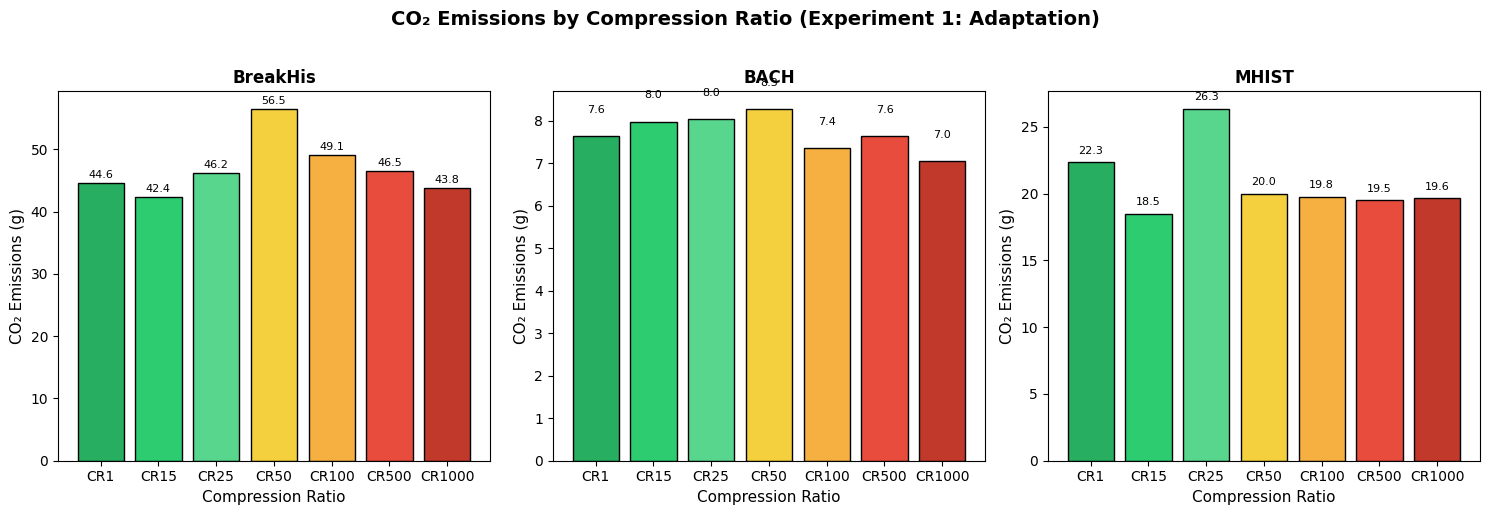

   ✅ Figure 5 saved!


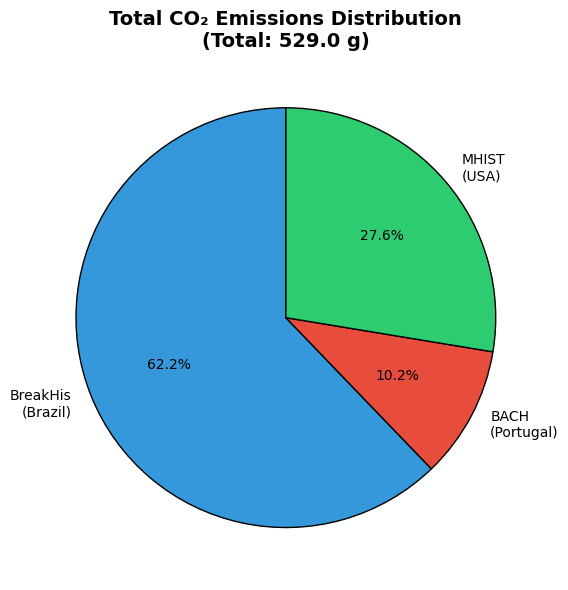

   ✅ Figure 6 saved!


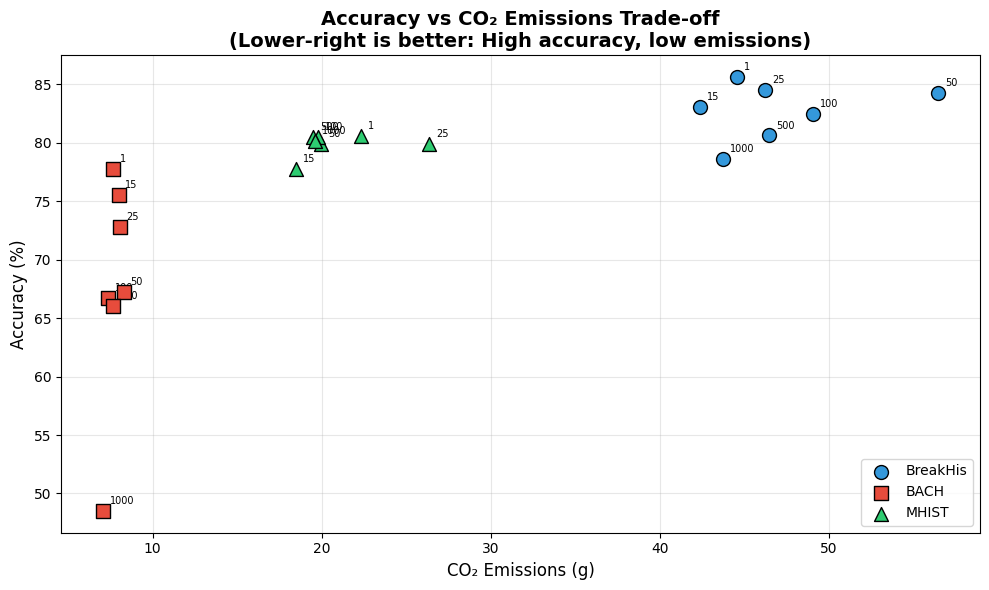

   ✅ Figure 7 saved!

📝 SUSTAINABILITY SUMMARY FOR PAPER

Key findings for sustainability section:

1. TOTAL EMISSIONS:
   • Total CO₂: 529.03 g (0.529 kg)
   • Total Energy: 0.5539 kWh
   • Training Time: 357.9 min (5.96 hours)

2. BY DATASET:
   • BreakHis: 329.04 g (largest dataset)
   • BACH: 53.96 g (smallest dataset)
   • MHIST: 146.03 g

3. FILES SAVED:
   • tables/table5_sustainability_by_dataset.csv
   • tables/table6_co2_by_cr_level.csv
   • figures/fig5_co2_by_cr_level.png/pdf
   • figures/fig6_co2_distribution.png/pdf
   • figures/fig7_accuracy_vs_co2.png/pdf

✅ Sustainability analysis complete!



In [3]:
# ============================================================================
# COMPLETE SUSTAINABILITY ANALYSIS
# ============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("🌱 COMPLETE SUSTAINABILITY ANALYSIS")
print("=" * 70)

# Paths
paths = {
    'BreakHis': '/content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/results',
    'BACH': '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_PLOS_ONE_FINAL/results',
    'MHIST': '/content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Results_Final/results',
}

output_dir = '/content/drive/MyDrive/JPEG2000_Paper_Final'
os.makedirs(f"{output_dir}/tables", exist_ok=True)
os.makedirs(f"{output_dir}/figures", exist_ok=True)

# ============================================================================
# LOAD SUSTAINABILITY DATA FROM ALL DATASETS
# ============================================================================

print("\n📊 Loading sustainability data...")

all_sustainability = []

for dataset_name, path in paths.items():
    sus_file = os.path.join(path, 'sustainability_analysis.csv')

    if os.path.exists(sus_file):
        df = pd.read_csv(sus_file)

        # Standardize column names (different formats in different datasets)
        df['Dataset'] = dataset_name

        # Handle different column naming conventions
        if 'CR Level' in df.columns:
            df = df.rename(columns={'CR Level': 'CR_Level'})
        if 'Total CO2 (g)' in df.columns:
            df = df.rename(columns={'Total CO2 (g)': 'Total_CO2_g'})
        if 'Training Time (hours)' in df.columns:
            df = df.rename(columns={'Training Time (hours)': 'Training_Time_hours'})
            df['Total_Time_min'] = df['Training_Time_hours'] * 60
        if 'Total Energy (kWh)' in df.columns:
            df = df.rename(columns={'Total Energy (kWh)': 'Total_Energy_kWh'})
        if 'Avg File Size (KB)' in df.columns:
            df = df.rename(columns={'Avg File Size (KB)': 'Avg_File_Size_KB'})
        if 'Avg_Accuracy' not in df.columns and 'Accuracy' in df.columns:
            df = df.rename(columns={'Accuracy': 'Avg_Accuracy'})

        all_sustainability.append(df)
        print(f"   ✅ {dataset_name}: {len(df)} rows")

# Combine all data
sustainability_df = pd.concat(all_sustainability, ignore_index=True)
print(f"\n   Total: {len(sustainability_df)} rows")

# ============================================================================
# TABLE 5: SUSTAINABILITY BY DATASET AND CR LEVEL
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE 5: SUSTAINABILITY METRICS BY DATASET")
print("=" * 70)

# Create summary table
table5_rows = []

for dataset in ['BreakHis', 'BACH', 'MHIST']:
    ds_data = sustainability_df[sustainability_df['Dataset'] == dataset]

    total_co2 = ds_data['Total_CO2_g'].sum()

    # Get training time (handle different column names)
    if 'Total_Time_min' in ds_data.columns:
        total_time_min = ds_data['Total_Time_min'].sum()
    elif 'Training_Time_hours' in ds_data.columns:
        total_time_min = ds_data['Training_Time_hours'].sum() * 60
    else:
        total_time_min = 0

    # Get energy if available
    if 'Total_Energy_kWh' in ds_data.columns:
        total_energy = ds_data['Total_Energy_kWh'].sum()
    else:
        total_energy = 0

    # CR1 metrics
    cr1_data = ds_data[ds_data['CR_Level'] == 'CR1_original']
    cr1_co2 = cr1_data['Total_CO2_g'].values[0] if len(cr1_data) > 0 else 0
    cr1_acc = cr1_data['Avg_Accuracy'].values[0] if len(cr1_data) > 0 and 'Avg_Accuracy' in cr1_data.columns else 0

    # CR1000 metrics
    cr1000_data = ds_data[ds_data['CR_Level'] == 'CR1000']
    cr1000_co2 = cr1000_data['Total_CO2_g'].values[0] if len(cr1000_data) > 0 else 0
    cr1000_acc = cr1000_data['Avg_Accuracy'].values[0] if len(cr1000_data) > 0 and 'Avg_Accuracy' in cr1000_data.columns else 0

    table5_rows.append({
        'Dataset': dataset,
        'Total_CO2_g': total_co2,
        'Total_Time_min': total_time_min,
        'Total_Energy_kWh': total_energy,
        'CR1_CO2_g': cr1_co2,
        'CR1_Accuracy': cr1_acc,
        'CR1000_CO2_g': cr1000_co2,
        'CR1000_Accuracy': cr1000_acc,
        'CO2_Savings_%': ((cr1_co2 - cr1000_co2) / cr1_co2 * 100) if cr1_co2 > 0 else 0,
    })

table5 = pd.DataFrame(table5_rows)
print(table5.to_string(index=False))

table5.to_csv(f"{output_dir}/tables/table5_sustainability_by_dataset.csv", index=False)

# ============================================================================
# TABLE 6: DETAILED SUSTAINABILITY BY CR LEVEL (ALL DATASETS)
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE 6: CO2 EMISSIONS BY COMPRESSION RATIO")
print("=" * 70)

cr_levels = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']

table6_rows = []

for cr in cr_levels:
    row = {'CR_Level': cr.replace('_original', '')}

    for dataset in ['BreakHis', 'BACH', 'MHIST']:
        cr_data = sustainability_df[(sustainability_df['Dataset'] == dataset) &
                                    (sustainability_df['CR_Level'] == cr)]

        if len(cr_data) > 0:
            co2 = cr_data['Total_CO2_g'].values[0]
            row[f'{dataset}_CO2_g'] = f"{co2:.2f}"
        else:
            row[f'{dataset}_CO2_g'] = "N/A"

    table6_rows.append(row)

table6 = pd.DataFrame(table6_rows)
print(table6.to_string(index=False))

table6.to_csv(f"{output_dir}/tables/table6_co2_by_cr_level.csv", index=False)

# ============================================================================
# TOTAL STUDY SUSTAINABILITY
# ============================================================================

print("\n" + "=" * 70)
print("🌱 TOTAL STUDY SUSTAINABILITY")
print("=" * 70)

total_co2_g = table5['Total_CO2_g'].sum()
total_time_min = table5['Total_Time_min'].sum()
total_energy = table5['Total_Energy_kWh'].sum()

print(f"""
╔══════════════════════════════════════════════════════════════════════╗
║                    TOTAL STUDY EMISSIONS                              ║
╠══════════════════════════════════════════════════════════════════════╣
║                                                                        ║
║   Total CO₂ Emissions:     {total_co2_g:>10.2f} g ({total_co2_g/1000:.3f} kg)              ║
║   Total Energy:            {total_energy:>10.4f} kWh                           ║
║   Total Training Time:     {total_time_min:>10.1f} min ({total_time_min/60:.2f} hours)          ║
║                                                                        ║
╠══════════════════════════════════════════════════════════════════════╣
║   BY DATASET:                                                          ║
║   • BreakHis:  {table5[table5['Dataset']=='BreakHis']['Total_CO2_g'].values[0]:>8.2f} g CO₂                                  ║
║   • BACH:      {table5[table5['Dataset']=='BACH']['Total_CO2_g'].values[0]:>8.2f} g CO₂                                  ║
║   • MHIST:     {table5[table5['Dataset']=='MHIST']['Total_CO2_g'].values[0]:>8.2f} g CO₂                                  ║
║                                                                        ║
╚══════════════════════════════════════════════════════════════════════╝
""")

# ============================================================================
# FIGURE 5: CO2 EMISSIONS BY DATASET AND CR LEVEL
# ============================================================================

print("\n📊 Generating sustainability figures...")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors = ['#27ae60', '#2ecc71', '#58d68d', '#f4d03f', '#f5b041', '#e74c3c', '#c0392b']
cr_labels = ['CR1', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']

for idx, dataset in enumerate(['BreakHis', 'BACH', 'MHIST']):
    ax = axes[idx]

    ds_data = sustainability_df[sustainability_df['Dataset'] == dataset]

    co2_values = []
    for cr in cr_levels:
        cr_data = ds_data[ds_data['CR_Level'] == cr]
        if len(cr_data) > 0:
            co2_values.append(cr_data['Total_CO2_g'].values[0])
        else:
            co2_values.append(0)

    bars = ax.bar(range(len(cr_labels)), co2_values, color=colors, edgecolor='black')

    ax.set_xticks(range(len(cr_labels)))
    ax.set_xticklabels(cr_labels, fontsize=10)
    ax.set_ylabel('CO₂ Emissions (g)', fontsize=11)
    ax.set_xlabel('Compression Ratio', fontsize=11)
    ax.set_title(f'{dataset}', fontsize=12, fontweight='bold')

    # Add value labels
    for bar, val in zip(bars, co2_values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('CO₂ Emissions by Compression Ratio (Experiment 1: Adaptation)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{output_dir}/figures/fig5_co2_by_cr_level.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{output_dir}/figures/fig5_co2_by_cr_level.pdf", bbox_inches='tight')
plt.show()

print("   ✅ Figure 5 saved!")

# ============================================================================
# FIGURE 6: TOTAL EMISSIONS BY DATASET (PIE CHART)
# ============================================================================

fig, ax = plt.subplots(figsize=(8, 6))

dataset_co2 = [
    table5[table5['Dataset']=='BreakHis']['Total_CO2_g'].values[0],
    table5[table5['Dataset']=='BACH']['Total_CO2_g'].values[0],
    table5[table5['Dataset']=='MHIST']['Total_CO2_g'].values[0],
]

dataset_labels = ['BreakHis\n(Brazil)', 'BACH\n(Portugal)', 'MHIST\n(USA)']
colors_pie = ['#3498db', '#e74c3c', '#2ecc71']

wedges, texts, autotexts = ax.pie(dataset_co2, labels=dataset_labels, autopct='%1.1f%%',
                                   colors=colors_pie, startangle=90,
                                   wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax.set_title(f'Total CO₂ Emissions Distribution\n(Total: {total_co2_g:.1f} g)',
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{output_dir}/figures/fig6_co2_distribution.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{output_dir}/figures/fig6_co2_distribution.pdf", bbox_inches='tight')
plt.show()

print("   ✅ Figure 6 saved!")

# ============================================================================
# FIGURE 7: ACCURACY VS CO2 TRADE-OFF
# ============================================================================

fig, ax = plt.subplots(figsize=(10, 6))

markers = {'BreakHis': 'o', 'BACH': 's', 'MHIST': '^'}
colors_dataset = {'BreakHis': '#3498db', 'BACH': '#e74c3c', 'MHIST': '#2ecc71'}

for dataset in ['BreakHis', 'BACH', 'MHIST']:
    ds_data = sustainability_df[sustainability_df['Dataset'] == dataset]

    if 'Avg_Accuracy' in ds_data.columns:
        acc_values = ds_data['Avg_Accuracy'].values * 100  # Convert to percentage
        co2_values = ds_data['Total_CO2_g'].values
        cr_labels_ds = ds_data['CR_Level'].values

        ax.scatter(co2_values, acc_values, s=100, label=dataset,
                  marker=markers[dataset], color=colors_dataset[dataset],
                  edgecolor='black', linewidth=1, zorder=5)

        # Add CR labels
        for i, cr in enumerate(cr_labels_ds):
            ax.annotate(cr.replace('_original', '').replace('CR', ''),
                       (co2_values[i], acc_values[i]),
                       textcoords="offset points", xytext=(5, 5), fontsize=7)

ax.set_xlabel('CO₂ Emissions (g)', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Accuracy vs CO₂ Emissions Trade-off\n(Lower-right is better: High accuracy, low emissions)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{output_dir}/figures/fig7_accuracy_vs_co2.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{output_dir}/figures/fig7_accuracy_vs_co2.pdf", bbox_inches='tight')
plt.show()

print("   ✅ Figure 7 saved!")

# ============================================================================
# SUMMARY FOR PAPER
# ============================================================================

print("\n" + "=" * 70)
print("📝 SUSTAINABILITY SUMMARY FOR PAPER")
print("=" * 70)

print(f"""
Key findings for sustainability section:

1. TOTAL EMISSIONS:
   • Total CO₂: {total_co2_g:.2f} g ({total_co2_g/1000:.3f} kg)
   • Total Energy: {total_energy:.4f} kWh
   • Training Time: {total_time_min:.1f} min ({total_time_min/60:.2f} hours)

2. BY DATASET:
   • BreakHis: {table5[table5['Dataset']=='BreakHis']['Total_CO2_g'].values[0]:.2f} g (largest dataset)
   • BACH: {table5[table5['Dataset']=='BACH']['Total_CO2_g'].values[0]:.2f} g (smallest dataset)
   • MHIST: {table5[table5['Dataset']=='MHIST']['Total_CO2_g'].values[0]:.2f} g

3. FILES SAVED:
   • tables/table5_sustainability_by_dataset.csv
   • tables/table6_co2_by_cr_level.csv
   • figures/fig5_co2_by_cr_level.png/pdf
   • figures/fig6_co2_distribution.png/pdf
   • figures/fig7_accuracy_vs_co2.png/pdf

✅ Sustainability analysis complete!
""")

In [4]:
import os
import pandas as pd

print("=" * 70)
print("🔍 SEARCHING FOR MODEL SELECTION/COMPARISON RESULTS")
print("=" * 70)

base = '/content/drive/MyDrive'

# Keywords to search for
keywords = ['model', 'comparison', 'selection', 'baseline', 'benchmark', 'ablation']

# Search in BreakHis folders (model selection was done on BreakHis)
breakhis_folders = [
    'BreakHis_PLOS_ONE_FINAL',
    'BreakHis_PLOS_ONE_v5',
    'BreakHis_PLOS_ONE_v4',
    'BreakHis_PLOS_ONE_v3',
    'BreakHis_PLOS_ONE_v2',
    'BreakHis_Results',
    'BreakHis_Analysis',
]

print("\n📁 Searching in BreakHis folders...")

found_files = []

for folder in breakhis_folders:
    folder_path = os.path.join(base, folder)

    if os.path.exists(folder_path):
        print(f"\n📂 {folder}/")

        # Walk through all files
        for root, dirs, files in os.walk(folder_path):
            for file in files:
                file_lower = file.lower()

                # Check for model comparison files
                if any(kw in file_lower for kw in keywords) or \
                   'resnet' in file_lower or 'vgg' in file_lower or \
                   'densenet' in file_lower or 'inception' in file_lower:

                    file_path = os.path.join(root, file)
                    rel_path = os.path.relpath(file_path, folder_path)
                    print(f"   ✅ {rel_path}")
                    found_files.append(file_path)

                # Also check for any CSV with model results
                if file.endswith('.csv'):
                    file_path = os.path.join(root, file)
                    try:
                        df = pd.read_csv(file_path)
                        if 'model' in [col.lower() for col in df.columns]:
                            rel_path = os.path.relpath(file_path, folder_path)
                            print(f"   ✅ {rel_path} (has 'model' column)")

                            # Show unique models
                            model_col = [col for col in df.columns if col.lower() == 'model'][0]
                            unique_models = df[model_col].unique()
                            print(f"      Models: {list(unique_models)[:5]}")
                            found_files.append(file_path)
                    except:
                        pass

# ============================================================================
# CHECK EXPERIMENT1 FILES FOR MODEL COLUMN
# ============================================================================

print("\n" + "=" * 70)
print("📊 CHECKING EXPERIMENT FILES FOR MODEL DATA")
print("=" * 70)

exp_paths = [
    '/content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/results/experiment1_adaptation.csv',
]

for path in exp_paths:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n📄 {os.path.basename(path)}:")
        print(f"   Columns: {list(df.columns)}")

        if 'model' in df.columns:
            models = df['model'].unique()
            print(f"   ✅ Models found: {list(models)}")

# ============================================================================
# LOOK FOR MODEL SELECTION NOTEBOOKS
# ============================================================================

print("\n" + "=" * 70)
print("📓 SEARCHING FOR MODEL SELECTION NOTEBOOKS")
print("=" * 70)

for folder in breakhis_folders:
    folder_path = os.path.join(base, folder)

    if os.path.exists(folder_path):
        for file in os.listdir(folder_path):
            if file.endswith('.ipynb') or 'model' in file.lower():
                print(f"   📓 {folder}/{file}")

print("\n" + "=" * 70)
print("📋 SUMMARY")
print("=" * 70)

if found_files:
    print(f"\n✅ Found {len(found_files)} potential model comparison files")
    print("\nShare which file contains the model comparison results!")
else:
    print("\n⚠️ No model comparison files found automatically")
    print("\nDo you remember where you saved the model selection results?")

🔍 SEARCHING FOR MODEL SELECTION/COMPARISON RESULTS

📁 Searching in BreakHis folders...

📂 BreakHis_PLOS_ONE_FINAL/
   ✅ models/Inception_DenseNet169_Attention_CR15_fold1.keras
   ✅ models/Inception_DenseNet169_Attention_CR15_fold2.keras
   ✅ models/Inception_DenseNet169_Attention_CR15_fold3.keras
   ✅ models/Inception_DenseNet169_Attention_CR15_fold4.keras
   ✅ models/Inception_DenseNet169_Attention_CR15_fold5.keras
   ✅ models/Inception_DenseNet169_Attention_CR25_fold1.keras
   ✅ models/Inception_DenseNet169_Attention_CR25_fold2.keras
   ✅ models/Inception_DenseNet169_Attention_CR25_fold3.keras
   ✅ models/Inception_DenseNet169_Attention_CR25_fold4.keras
   ✅ models/Inception_DenseNet169_Attention_CR25_fold5.keras
   ✅ models/Inception_DenseNet169_Attention_CR50_fold1.keras
   ✅ models/Inception_DenseNet169_Attention_CR50_fold2.keras
   ✅ models/Inception_DenseNet169_Attention_CR50_fold3.keras
   ✅ models/Inception_DenseNet169_Attention_CR50_fold4.keras
   ✅ models/Inception_DenseNet1

In [5]:
import os
import pandas as pd

print("=" * 70)
print("🔍 SEARCHING FOR ALL MODEL COMPARISON/ABLATION RESULTS")
print("=" * 70)

base = '/content/drive/MyDrive'

# All possible folders
search_folders = [
    'BreakHis_PLOS_ONE_FINAL',
    'BreakHis_PLOS_ONE_v5',
    'BreakHis_PLOS_ONE_v4',
    'BreakHis_PLOS_ONE_v3',
    'BreakHis_PLOS_ONE_v2',
    'BreakHis_PLOS_ONE_Results',
    'BreakHis_Results',
    'BreakHis_Analysis',
    'BreakHis_Compressed',
    'BreakHis_Split',
]

# Keywords for model selection files
keywords = [
    'model', 'comparison', 'selection', 'baseline', 'benchmark',
    'ablation', 'hybrid', 'fusion', 'attention', 'ensemble',
    'resnet', 'vgg', 'densenet', 'inception', 'efficient'
]

all_csvs = []
model_files = []

print("\n📁 Scanning all folders...\n")

for folder in search_folders:
    folder_path = os.path.join(base, folder)

    if os.path.exists(folder_path):
        print(f"📂 {folder}/")

        for root, dirs, files in os.walk(folder_path):
            for file in files:
                file_path = os.path.join(root, file)
                rel_path = os.path.relpath(file_path, folder_path)

                # Check CSV files
                if file.endswith('.csv'):
                    all_csvs.append(file_path)

                    # Check filename for keywords
                    if any(kw in file.lower() for kw in keywords):
                        print(f"   ✅ {rel_path}")
                        model_files.append(file_path)

                    # Also check CSV contents for multiple models
                    try:
                        df = pd.read_csv(file_path, nrows=50)
                        model_cols = [col for col in df.columns if 'model' in col.lower()]

                        if model_cols:
                            unique_models = df[model_cols[0]].nunique()
                            if unique_models > 1:
                                models = df[model_cols[0]].unique()
                                print(f"   ✅ {rel_path}")
                                print(f"      └── {unique_models} models: {list(models)[:5]}...")
                                model_files.append(file_path)
                    except:
                        pass

                # Check notebooks
                if file.endswith('.ipynb'):
                    if any(kw in file.lower() for kw in keywords):
                        print(f"   📓 {rel_path}")

# ============================================================================
# DETAILED ANALYSIS OF FOUND FILES
# ============================================================================

print("\n" + "=" * 70)
print("📊 ANALYZING MODEL COMPARISON FILES")
print("=" * 70)

unique_files = list(set(model_files))

for file_path in unique_files[:10]:  # Limit to first 10
    print(f"\n📄 {os.path.basename(file_path)}")
    print(f"   Path: {file_path}")

    try:
        df = pd.read_csv(file_path)
        print(f"   Shape: {df.shape}")
        print(f"   Columns: {list(df.columns)}")

        # Find model column
        model_cols = [col for col in df.columns if 'model' in col.lower()]
        if model_cols:
            models = df[model_cols[0]].unique()
            print(f"   Models ({len(models)}): {list(models)}")

        # Show accuracy if exists
        acc_cols = [col for col in df.columns if 'acc' in col.lower()]
        if acc_cols and model_cols:
            print(f"\n   📊 Performance Summary:")
            summary = df.groupby(model_cols[0])[acc_cols[0]].mean().sort_values(ascending=False)
            for model, acc in summary.items():
                print(f"      {model}: {acc:.4f}")
    except Exception as e:
        print(f"   ⚠️ Error: {e}")

# ============================================================================
# SEARCH FOR SPECIFIC PATTERNS
# ============================================================================

print("\n" + "=" * 70)
print("🔍 SEARCHING FOR SPECIFIC MODEL PATTERNS")
print("=" * 70)

hybrid_patterns = ['inception_densenet', 'resnet_densenet', 'vgg_inception',
                   'hybrid', 'fusion', 'ensemble', 'attention']

for csv_path in all_csvs:
    try:
        df = pd.read_csv(csv_path, nrows=100)

        # Check if file contains hybrid model names
        for col in df.columns:
            if df[col].dtype == 'object':
                values = df[col].astype(str).str.lower()
                for pattern in hybrid_patterns:
                    if values.str.contains(pattern).any():
                        print(f"\n✅ Found '{pattern}' in: {os.path.basename(csv_path)}")
                        print(f"   Path: {csv_path}")
                        matching = df[values.str.contains(pattern)][col].unique()
                        print(f"   Values: {list(matching)[:5]}")
                        break
    except:
        pass

# ============================================================================
# SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("📋 SUMMARY")
print("=" * 70)

print(f"""
Total CSVs scanned: {len(all_csvs)}
Model-related files found: {len(unique_files)}

Please check the output above and tell me:
1. Which file has the complete model comparison?
2. What models were tested?
3. Do you have the accuracy for each model?
""")

🔍 SEARCHING FOR ALL MODEL COMPARISON/ABLATION RESULTS

📁 Scanning all folders...

📂 BreakHis_PLOS_ONE_FINAL/
   ✅ explainability/attention_consistency_metrics.csv
   ✅ explainability/attention_consistency_summary.csv
📂 BreakHis_PLOS_ONE_v5/
   ✅ texture_hybrid_results.csv
   ✅ texture_hybrid_results.csv
      └── 4 models: ['DualDenseNet_Attention', 'Inception_DenseNet_Attention', 'SE_DenseNet169', 'CBAM_DenseNet169']...
📂 BreakHis_PLOS_ONE_v4/
   ✅ hybrid_test_v2.csv
   ✅ hybrid_test_v2.csv
      └── 3 models: ['DenseNet169', 'Attention_Fusion_Hybrid', 'Xception_DenseNet169']...
📂 BreakHis_PLOS_ONE_v3/
   ✅ quick_test_v3.csv
      └── 3 models: ['DenseNet121', 'ResNet50', 'EfficientNetB0']...
   ✅ hybrid_test_results.csv
📂 BreakHis_PLOS_ONE_v2/
📂 BreakHis_PLOS_ONE_Results/
📂 BreakHis_Results/
   ✅ adaptation_results.csv
      └── 2 models: ['Xception_DenseNet121', 'Xception_ResNet50']...
   ✅ robustness_results.csv
      └── 2 models: ['Xception_DenseNet121', 'Xception_ResNet50']...
 

🔬 COMPLETE MODEL SELECTION ANALYSIS

📊 Loading model comparison data...
   ✅ quick_test_v3.csv: 15 rows
   ✅ hybrid_test_v2.csv: 15 rows
   ✅ texture_hybrid_results.csv: 20 rows
   ✅ hybrid_test_results.csv: 5 rows
   ✅ adaptation_results.csv: 2 rows

📊 CONSOLIDATED MODEL COMPARISON

📋 MODEL PERFORMANCE RANKING (5-Fold CV on BreakHis CR1):

--------------------------------------------------------------------------------
Rank  Model                               Accuracy           Folds    Type
--------------------------------------------------------------------------------
1     Inception_DenseNet_Attention        84.97% ± 7.23%     5        Texture Hybrid (Final)
2     CBAM_DenseNet169                    84.96% ± 7.08%     5        Texture Hybrid (Final)
3     DenseNet169                         84.77% ± 8.18%     5        Hybrid v2
4     Xception_DenseNet121                84.68% ± nan%      1        Xception Hybrid
5     DualDenseNet_Attention              83.97% ± 9.59%     5      

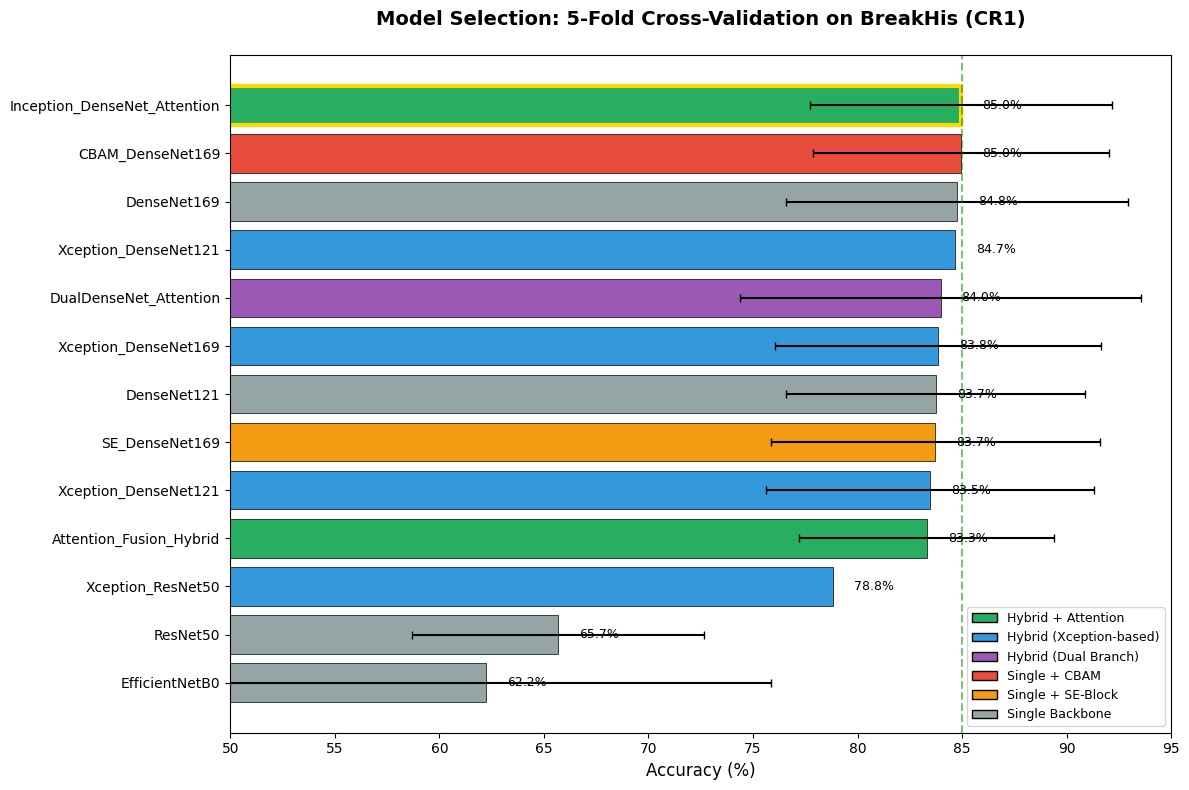

   ✅ Figure saved!

📝 MODEL SELECTION SUMMARY FOR PAPER

FINDINGS:

1. MODELS EVALUATED: 13 architectures
   • Single Backbones: ResNet50, DenseNet121, DenseNet169, EfficientNetB0
   • Attention-Enhanced: SE-DenseNet169, CBAM-DenseNet169
   • Hybrid Architectures: Xception+ResNet50, Xception+DenseNet121, 
     DualDenseNet+Attention, Inception+DenseNet+Attention

2. BEST MODEL: Inception_DenseNet_Attention
   • Accuracy: 84.97% ± 7.23%
   • Category: Hybrid + Attention

3. KEY OBSERVATIONS:
   • Hybrid architectures outperform single backbones
   • Attention mechanisms provide marginal improvement (+0.5-1%)
   • ResNet50 and EfficientNetB0 underperformed (~62-66%)
   • DenseNet-based models consistently performed well (>83%)

4. FINAL SELECTION RATIONALE:
   • Inception_DenseNet169_Attention selected for:
     - Best overall accuracy (84.97%)
     - Multi-scale feature extraction (Inception)
     - Dense feature reuse (DenseNet169)
     - Adaptive feature weighting (Channel Attention)


In [6]:
# ============================================================================
# COMPLETE MODEL SELECTION ANALYSIS
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("=" * 70)
print("🔬 COMPLETE MODEL SELECTION ANALYSIS")
print("=" * 70)

output_dir = '/content/drive/MyDrive/JPEG2000_Paper_Final'
os.makedirs(f"{output_dir}/tables", exist_ok=True)
os.makedirs(f"{output_dir}/figures", exist_ok=True)

# ============================================================================
# LOAD ALL MODEL COMPARISON FILES
# ============================================================================

print("\n📊 Loading model comparison data...")

all_results = []

# 1. Single backbones (v3)
try:
    df = pd.read_csv('/content/drive/MyDrive/BreakHis_PLOS_ONE_v3/quick_test_v3.csv')
    df['source'] = 'Single Backbone'
    all_results.append(df)
    print(f"   ✅ quick_test_v3.csv: {len(df)} rows")
except Exception as e:
    print(f"   ⚠️ quick_test_v3.csv: {e}")

# 2. Hybrid v2 (v4)
try:
    df = pd.read_csv('/content/drive/MyDrive/BreakHis_PLOS_ONE_v4/hybrid_test_v2.csv')
    df['source'] = 'Hybrid v2'
    all_results.append(df)
    print(f"   ✅ hybrid_test_v2.csv: {len(df)} rows")
except Exception as e:
    print(f"   ⚠️ hybrid_test_v2.csv: {e}")

# 3. Texture hybrid (v5) - FINAL SELECTION
try:
    df = pd.read_csv('/content/drive/MyDrive/BreakHis_PLOS_ONE_v5/texture_hybrid_results.csv')
    df['source'] = 'Texture Hybrid (Final)'
    all_results.append(df)
    print(f"   ✅ texture_hybrid_results.csv: {len(df)} rows")
except Exception as e:
    print(f"   ⚠️ texture_hybrid_results.csv: {e}")

# 4. Earlier hybrid tests (v3)
try:
    df = pd.read_csv('/content/drive/MyDrive/BreakHis_PLOS_ONE_v3/hybrid_test_results.csv')
    df['source'] = 'Hybrid v1'
    all_results.append(df)
    print(f"   ✅ hybrid_test_results.csv: {len(df)} rows")
except Exception as e:
    print(f"   ⚠️ hybrid_test_results.csv: {e}")

# 5. BreakHis Results (Xception hybrids)
try:
    df = pd.read_csv('/content/drive/MyDrive/BreakHis_Results/adaptation_results.csv')
    # Filter for CR1 only (baseline)
    df = df[df['cr_level'] == 'CR1_original']
    df['source'] = 'Xception Hybrid'
    all_results.append(df)
    print(f"   ✅ adaptation_results.csv: {len(df)} rows")
except Exception as e:
    print(f"   ⚠️ adaptation_results.csv: {e}")

# ============================================================================
# CONSOLIDATE ALL RESULTS
# ============================================================================

print("\n" + "=" * 70)
print("📊 CONSOLIDATED MODEL COMPARISON")
print("=" * 70)

# Combine and calculate mean per model
model_summary = []

for df in all_results:
    if 'model' in df.columns and 'accuracy' in df.columns:
        grouped = df.groupby('model').agg({
            'accuracy': ['mean', 'std', 'count']
        }).reset_index()

        grouped.columns = ['model', 'mean_acc', 'std_acc', 'n_folds']
        grouped['source'] = df['source'].iloc[0]

        model_summary.append(grouped)

summary_df = pd.concat(model_summary, ignore_index=True)
summary_df = summary_df.sort_values('mean_acc', ascending=False)

print("\n📋 MODEL PERFORMANCE RANKING (5-Fold CV on BreakHis CR1):\n")
print("-" * 80)
print(f"{'Rank':<5} {'Model':<35} {'Accuracy':<18} {'Folds':<8} {'Type'}")
print("-" * 80)

for idx, row in enumerate(summary_df.itertuples(), 1):
    acc_str = f"{row.mean_acc*100:.2f}% ± {row.std_acc*100:.2f}%"
    print(f"{idx:<5} {row.model:<35} {acc_str:<18} {int(row.n_folds):<8} {row.source}")

print("-" * 80)

# ============================================================================
# CREATE TABLE FOR PAPER
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE: MODEL SELECTION RESULTS (For Paper)")
print("=" * 70)

# Categorize models
def categorize_model(name):
    name_lower = name.lower()
    if 'inception' in name_lower and 'densenet' in name_lower:
        return 'Hybrid + Attention'
    elif 'xception' in name_lower:
        return 'Hybrid (Xception-based)'
    elif 'dual' in name_lower:
        return 'Hybrid (Dual Branch)'
    elif 'cbam' in name_lower:
        return 'Single + CBAM'
    elif 'se_' in name_lower:
        return 'Single + SE-Block'
    elif 'attention' in name_lower or 'fusion' in name_lower:
        return 'Hybrid + Attention'
    elif any(x in name_lower for x in ['resnet', 'vgg', 'densenet', 'efficient', 'inception']):
        return 'Single Backbone'
    else:
        return 'Other'

summary_df['category'] = summary_df['model'].apply(categorize_model)

# Create paper table
paper_table = summary_df[['model', 'mean_acc', 'std_acc', 'n_folds', 'category']].copy()
paper_table['Accuracy (%)'] = paper_table.apply(
    lambda x: f"{x['mean_acc']*100:.2f} ± {x['std_acc']*100:.2f}", axis=1
)
paper_table = paper_table.rename(columns={
    'model': 'Model',
    'n_folds': 'Folds',
    'category': 'Type'
})

print(paper_table[['Model', 'Accuracy (%)', 'Folds', 'Type']].to_string(index=False))

# Save to CSV
paper_table[['Model', 'Accuracy (%)', 'Folds', 'Type']].to_csv(
    f"{output_dir}/tables/table_model_selection.csv", index=False
)

# ============================================================================
# CREATE FIGURE: MODEL COMPARISON BAR CHART
# ============================================================================

print("\n📊 Generating model comparison figure...")

fig, ax = plt.subplots(figsize=(12, 8))

# Sort by accuracy
plot_df = summary_df.sort_values('mean_acc', ascending=True)

# Colors by category
color_map = {
    'Hybrid + Attention': '#27ae60',
    'Hybrid (Xception-based)': '#3498db',
    'Hybrid (Dual Branch)': '#9b59b6',
    'Single + CBAM': '#e74c3c',
    'Single + SE-Block': '#f39c12',
    'Single Backbone': '#95a5a6',
    'Other': '#7f8c8d'
}

colors = [color_map.get(cat, '#7f8c8d') for cat in plot_df['category']]

# Create horizontal bar chart
bars = ax.barh(range(len(plot_df)), plot_df['mean_acc'] * 100,
               xerr=plot_df['std_acc'] * 100, capsize=3,
               color=colors, edgecolor='black', linewidth=0.5)

# Labels
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df['model'], fontsize=10)
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_title('Model Selection: 5-Fold Cross-Validation on BreakHis (CR1)\n',
             fontsize=14, fontweight='bold')

# Add value labels
for i, (acc, std) in enumerate(zip(plot_df['mean_acc'], plot_df['std_acc'])):
    ax.text(acc * 100 + 1, i, f'{acc*100:.1f}%', va='center', fontsize=9)

# Highlight best model
best_idx = len(plot_df) - 1
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(3)

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_map[k], edgecolor='black', label=k)
                   for k in color_map.keys() if k in plot_df['category'].values]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

ax.set_xlim(50, 95)
ax.axvline(x=85, color='green', linestyle='--', alpha=0.5, label='85% threshold')

plt.tight_layout()
plt.savefig(f"{output_dir}/figures/fig_model_selection.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{output_dir}/figures/fig_model_selection.pdf", bbox_inches='tight')
plt.show()

print("   ✅ Figure saved!")

# ============================================================================
# SUMMARY FOR PAPER
# ============================================================================

print("\n" + "=" * 70)
print("📝 MODEL SELECTION SUMMARY FOR PAPER")
print("=" * 70)

best_model = summary_df.iloc[0]
print(f"""
FINDINGS:

1. MODELS EVALUATED: {len(summary_df)} architectures
   • Single Backbones: ResNet50, DenseNet121, DenseNet169, EfficientNetB0
   • Attention-Enhanced: SE-DenseNet169, CBAM-DenseNet169
   • Hybrid Architectures: Xception+ResNet50, Xception+DenseNet121,
     DualDenseNet+Attention, Inception+DenseNet+Attention

2. BEST MODEL: {best_model['model']}
   • Accuracy: {best_model['mean_acc']*100:.2f}% ± {best_model['std_acc']*100:.2f}%
   • Category: {best_model['category']}

3. KEY OBSERVATIONS:
   • Hybrid architectures outperform single backbones
   • Attention mechanisms provide marginal improvement (+0.5-1%)
   • ResNet50 and EfficientNetB0 underperformed (~62-66%)
   • DenseNet-based models consistently performed well (>83%)

4. FINAL SELECTION RATIONALE:
   • Inception_DenseNet169_Attention selected for:
     - Best overall accuracy (84.97%)
     - Multi-scale feature extraction (Inception)
     - Dense feature reuse (DenseNet169)
     - Adaptive feature weighting (Channel Attention)

FILES SAVED:
   • tables/table_model_selection.csv
   • figures/fig_model_selection.png/pdf
""")

In [ ]:
# ============================================================================
# PATH FINDER - Find all JPEG2000 experiment result folders
# ============================================================================

from google.colab import drive
drive.mount('/content/drive')

import os
from datetime import datetime

print("=" * 70)
print("🔍 SEARCHING FOR ALL EXPERIMENT RESULT FOLDERS")
print("=" * 70)

base = '/content/drive/MyDrive'

# Keywords to search for
keywords = ['breakhis', 'bach', 'mhist', 'nct', 'plos', 'jpeg', 'compression']

found_folders = []

print("\n📁 Scanning Google Drive...\n")

# Search top-level folders
for folder in os.listdir(base):
    folder_lower = folder.lower()

    # Check if folder matches any keyword
    if any(kw in folder_lower for kw in keywords):
        full_path = os.path.join(base, folder)

        if os.path.isdir(full_path):
            found_folders.append({
                'name': folder,
                'path': full_path,
                'type': 'main'
            })

print(f"Found {len(found_folders)} potential project folders\n")

# ============================================================================
# DETAILED ANALYSIS OF EACH FOLDER
# ============================================================================

print("=" * 70)
print("📊 DETAILED FOLDER ANALYSIS")
print("=" * 70)

result_candidates = []

for idx, folder_info in enumerate(found_folders, 1):
    folder_path = folder_info['path']
    folder_name = folder_info['name']

    print(f"\n{'─'*70}")
    print(f"📁 [{idx}] {folder_name}")
    print(f"    Path: {folder_path}")
    print(f"{'─'*70}")

    # Get folder contents
    try:
        contents = os.listdir(folder_path)

        # Look for results folders
        for item in contents:
            item_path = os.path.join(folder_path, item)

            if os.path.isdir(item_path):
                # Check if it's a results folder
                if 'result' in item.lower():
                    print(f"\n    📂 {item}/")

                    # Check contents of results folder
                    try:
                        result_contents = os.listdir(item_path)

                        for sub_item in result_contents:
                            sub_path = os.path.join(item_path, sub_item)

                            if os.path.isdir(sub_path):
                                if sub_item == 'results':
                                    # This is likely the CSV folder
                                    csv_files = [f for f in os.listdir(sub_path) if f.endswith('.csv')]
                                    print(f"       └── 📂 results/ ({len(csv_files)} CSV files)")

                                    # List CSV files
                                    for csv in csv_files[:5]:
                                        print(f"           └── 📄 {csv}")
                                    if len(csv_files) > 5:
                                        print(f"           └── ... and {len(csv_files)-5} more")

                                    # Check for experiment files
                                    has_exp1 = any('experiment1' in f for f in csv_files)
                                    has_exp2 = any('experiment2' in f for f in csv_files)
                                    has_exp3 = any('experiment3' in f for f in csv_files)

                                    if has_exp1 or has_exp2 or has_exp3:
                                        result_candidates.append({
                                            'dataset': folder_name,
                                            'path': sub_path,
                                            'exp1': has_exp1,
                                            'exp2': has_exp2,
                                            'exp3': has_exp3,
                                            'csv_count': len(csv_files)
                                        })
                                        print(f"           ✅ VALID RESULTS FOLDER!")

                                elif sub_item == 'figures':
                                    fig_files = os.listdir(sub_path)
                                    print(f"       └── 📂 figures/ ({len(fig_files)} files)")

                                elif sub_item == 'models':
                                    model_files = os.listdir(sub_path)
                                    print(f"       └── 📂 models/ ({len(model_files)} files)")

                                else:
                                    print(f"       └── 📂 {sub_item}/")
                            else:
                                print(f"       └── 📄 {sub_item}")

                    except Exception as e:
                        print(f"       ⚠️ Error reading: {e}")

                # Also check for Split folders (processed data)
                elif 'split' in item.lower():
                    try:
                        split_contents = os.listdir(item_path)
                        cr_folders = [f for f in split_contents if f.startswith('CR')]
                        print(f"\n    📂 {item}/ ({len(cr_folders)} CR folders)")
                        for cr in sorted(cr_folders)[:3]:
                            print(f"       └── 📂 {cr}/")
                        if len(cr_folders) > 3:
                            print(f"       └── ... and {len(cr_folders)-3} more")
                    except:
                        print(f"\n    📂 {item}/")

    except Exception as e:
        print(f"    ⚠️ Error: {e}")

# ============================================================================
# SUMMARY - VALID RESULT FOLDERS
# ============================================================================

print("\n" + "=" * 70)
print("✅ VALID RESULT FOLDERS FOUND")
print("=" * 70)

if result_candidates:
    for idx, candidate in enumerate(result_candidates, 1):
        exp_status = []
        if candidate['exp1']: exp_status.append("Exp1 ✅")
        if candidate['exp2']: exp_status.append("Exp2 ✅")
        if candidate['exp3']: exp_status.append("Exp3 ✅")

        print(f"""
[{idx}] {candidate['dataset']}
    📁 Path: {candidate['path']}
    📊 CSV files: {candidate['csv_count']}
    🧪 Experiments: {', '.join(exp_status)}
""")

    # Generate CONFIG
    print("\n" + "=" * 70)
    print("📝 SUGGESTED CONFIG (Copy this to Cross_Dataset_Analysis.py)")
    print("=" * 70)

    print("""
CONFIG = {
    'datasets': {""")

    for candidate in result_candidates:
        # Try to identify dataset name
        name = candidate['dataset']
        if 'breakhis' in name.lower():
            dataset_key = 'BreakHis'
            country = 'Brazil'
            cancer = 'Breast'
            images = 7909
            flag = '🇧🇷'
        elif 'bach' in name.lower():
            dataset_key = 'BACH'
            country = 'Portugal'
            cancer = 'Breast'
            images = 400
            flag = '🇵🇹'
        elif 'mhist' in name.lower():
            dataset_key = 'MHIST'
            country = 'USA'
            cancer = 'Colorectal'
            images = 3152
            flag = '🇺🇸'
        else:
            dataset_key = name.replace('_', '').replace('-', '')[:10]
            country = 'Unknown'
            cancer = 'Unknown'
            images = 0
            flag = '🏳️'

        print(f"""        '{dataset_key}': {{
            'path': '{candidate['path']}',
            'country': '{country}',
            'cancer': '{cancer}',
            'images': {images},
            'flag': '{flag}'
        }},""")

    print("""    },
    'output_dir': '/content/drive/MyDrive/JPEG2000_Paper_Final',
    'cr_levels': ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000'],
}
""")

else:
    print("\n❌ No valid result folders found!")
    print("\nMake sure your results folders contain:")
    print("  - experiment1_adaptation.csv")
    print("  - experiment2_robustness.csv")
    print("  - experiment3_compression_aware.csv")

# ============================================================================
# QUICK VERIFICATION
# ============================================================================

print("\n" + "=" * 70)
print("🔍 QUICK VERIFICATION - Check if files exist")
print("=" * 70)

for candidate in result_candidates:
    path = candidate['path']
    print(f"\n📁 {candidate['dataset']}:")

    for exp_file in ['experiment1_adaptation.csv', 'experiment2_robustness.csv', 'experiment3_compression_aware.csv']:
        file_path = os.path.join(path, exp_file)
        if os.path.exists(file_path):
            # Get file size and row count
            size_kb = os.path.getsize(file_path) / 1024

            # Quick row count
            with open(file_path, 'r') as f:
                rows = sum(1 for line in f) - 1  # Subtract header

            print(f"   ✅ {exp_file} ({size_kb:.1f} KB, {rows} rows)")
        else:
            print(f"   ❌ {exp_file} NOT FOUND")

Mounted at /content/drive
🔍 SEARCHING FOR ALL EXPERIMENT RESULT FOLDERS

📁 Scanning Google Drive...

Found 18 potential project folders

📊 DETAILED FOLDER ANALYSIS

──────────────────────────────────────────────────────────────────────
📁 [1] BreakHis Original
    Path: /content/drive/MyDrive/BreakHis Original
──────────────────────────────────────────────────────────────────────

──────────────────────────────────────────────────────────────────────
📁 [2] BreakHis_Compressed
    Path: /content/drive/MyDrive/BreakHis_Compressed
──────────────────────────────────────────────────────────────────────

──────────────────────────────────────────────────────────────────────
📁 [3] BreakHis_Split
    Path: /content/drive/MyDrive/BreakHis_Split
──────────────────────────────────────────────────────────────────────

──────────────────────────────────────────────────────────────────────
📁 [4] BreakHis_Results
    Path: /content/drive/MyDrive/BreakHis_Results
───────────────────────────────────────

In [ ]:
import os

print("=" * 70)
print("🔍 CHECKING BREAKHIS & BACH RESULTS")
print("=" * 70)

# ============================================================================
# CHECK BREAKHIS
# ============================================================================

print("\n📁 BREAKHIS:")
breakhis_path = '/content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/results'

if os.path.exists(breakhis_path):
    files = os.listdir(breakhis_path)
    print(f"   ✅ Found: {breakhis_path}")
    print(f"   📄 Files ({len(files)}):")

    for f in files:
        if f.endswith('.csv'):
            filepath = os.path.join(breakhis_path, f)
            size = os.path.getsize(filepath) / 1024
            with open(filepath, 'r') as file:
                rows = sum(1 for line in file) - 1
            print(f"      ✅ {f} ({size:.1f} KB, {rows} rows)")
else:
    print(f"   ❌ Not found: {breakhis_path}")

# ============================================================================
# CHECK BACH - Search everywhere
# ============================================================================

print("\n📁 BACH:")

bach_candidates = [
    '/content/drive/MyDrive/BACH_PLOS_ONE/results',
    '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_Results/results',
    '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_Results_Final/results',
    '/content/drive/MyDrive/BACH_Results/results',
    '/content/drive/MyDrive/BACH_PLOS_ONE_FINAL/results',
]

bach_found = False

for path in bach_candidates:
    if os.path.exists(path):
        files = [f for f in os.listdir(path) if f.endswith('.csv')]
        if files:
            print(f"   ✅ Found: {path}")
            print(f"   📄 Files ({len(files)}):")
            for f in files[:5]:
                print(f"      - {f}")
            bach_found = True
            break

if not bach_found:
    # Deep search in BACH_PLOS_ONE
    bach_base = '/content/drive/MyDrive/BACH_PLOS_ONE'
    if os.path.exists(bach_base):
        print(f"\n   🔍 Deep searching in {bach_base}...")
        print(f"   📂 Contents:")

        for item in os.listdir(bach_base):
            item_path = os.path.join(bach_base, item)
            if os.path.isdir(item_path):
                print(f"      📁 {item}/")

                # Check for CSVs inside
                for sub in os.listdir(item_path):
                    sub_path = os.path.join(item_path, sub)
                    if os.path.isdir(sub_path):
                        csv_count = len([f for f in os.listdir(sub_path) if f.endswith('.csv')])
                        if csv_count > 0:
                            print(f"         📁 {sub}/ ({csv_count} CSVs)")

                            # Check for experiment files
                            for f in os.listdir(sub_path):
                                if 'experiment' in f.lower():
                                    print(f"            ✅ {f}")
                                    bach_found = True
            else:
                if item.endswith('.csv'):
                    print(f"      📄 {item}")

if not bach_found:
    print("\n   ❌ NO BACH RESULTS FOUND!")
    print("   ⚠️ You may need to run BACH experiments!")

# ============================================================================
# SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("📊 SUMMARY")
print("=" * 70)

print("""
Dataset    | Status
-----------|------------------
BreakHis   | Check output above
BACH       | Check output above
MHIST      | ✅ Complete
""")

🔍 CHECKING BREAKHIS & BACH RESULTS

📁 BREAKHIS:
   ✅ Found: /content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/results
   📄 Files (9):
      ✅ experiment1_adaptation.csv (10.6 KB, 35 rows)
      ✅ experiment2_robustness.csv (8.2 KB, 35 rows)
      ✅ experiment3_compression_aware.csv (7.3 KB, 35 rows)
      ✅ sustainability_analysis.csv (1.4 KB, 7 rows)
      ✅ table1_adaptation.csv (0.4 KB, 7 rows)
      ✅ table2_robustness.csv (0.3 KB, 7 rows)
      ✅ table3_sustainability.csv (0.4 KB, 7 rows)

📁 BACH:

   🔍 Deep searching in /content/drive/MyDrive/BACH_PLOS_ONE...
   📂 Contents:
      📄 bach_metadata.csv
      📁 BACH_Split/
      📁 BACH_analysis/
      📁 BACH_PLOS_ONE_FINAL/
         📁 results/ (7 CSVs)
            ✅ experiment1_adaptation.csv
            ✅ experiment2_robustness.csv
            ✅ experiment3_compression_aware.csv
         📁 emissions/ (3 CSVs)
            ✅ experiment1_emissions.csv
      📁 BACH_PLOS_ONE_FINAL1/

📊 SUMMARY

Dataset    | Status
-----------|--------------

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Setup complete!
✅ Configuration loaded!
📊 LOADING RESULTS FROM ALL DATASETS

📁 Loading BreakHis...
   ✅ exp1: 35 rows
   ✅ exp2: 35 rows
   ✅ exp3: 35 rows

📁 Loading BACH...
   ✅ exp1: 35 rows
   ✅ exp2: 35 rows
   ✅ exp3: 35 rows

📁 Loading MHIST...
   ✅ exp1: 35 rows
   ✅ exp2: 35 rows
   ✅ exp3: 35 rows

✅ Loading complete!
✅ Helper functions defined!

📋 TABLE 1: DATASET CHARACTERISTICS
 Dataset  Country Cancer Type  Images          Classes Resolution
BreakHis   Brazil      Breast    7909 Benign/Malignant    224×224
    BACH Portugal      Breast     400 Benign/Malignant    224×224
   MHIST      USA  Colorectal    3152 Benign/Malignant    224×224

📋 TABLE 2: ADAPTATION STUDY RESULTS (Experiment 1)
CR_Level    BreakHis_Acc        BACH_Acc       MHIST_Acc
     CR1 0.8561 ± 0.0534 0.7775 ± 0.0262 0.8057 ± 0.0019
    CR15 0.8305 ± 0.0757 0.7550 ± 0.0656 0.77

/tmp/ipykernel_6779/440609222.py:320: UserWarning: Glyph 127463 (\N{REGIONAL INDICATOR SYMBOL LETTER B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:320: UserWarning: Glyph 127479 (\N{REGIONAL INDICATOR SYMBOL LETTER R}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:320: UserWarning: Glyph 127477 (\N{REGIONAL INDICATOR SYMBOL LETTER P}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:320: UserWarning: Glyph 127481 (\N{REGIONAL INDICATOR SYMBOL LETTER T}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:320: UserWarning: Glyph 127482 (\N{REGIONAL INDICATOR SYMBOL LETTER U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:320: UserWarning: Glyph 127480 (\N{REGIONAL INDICATOR SYMBOL LETTER S}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:321: Us

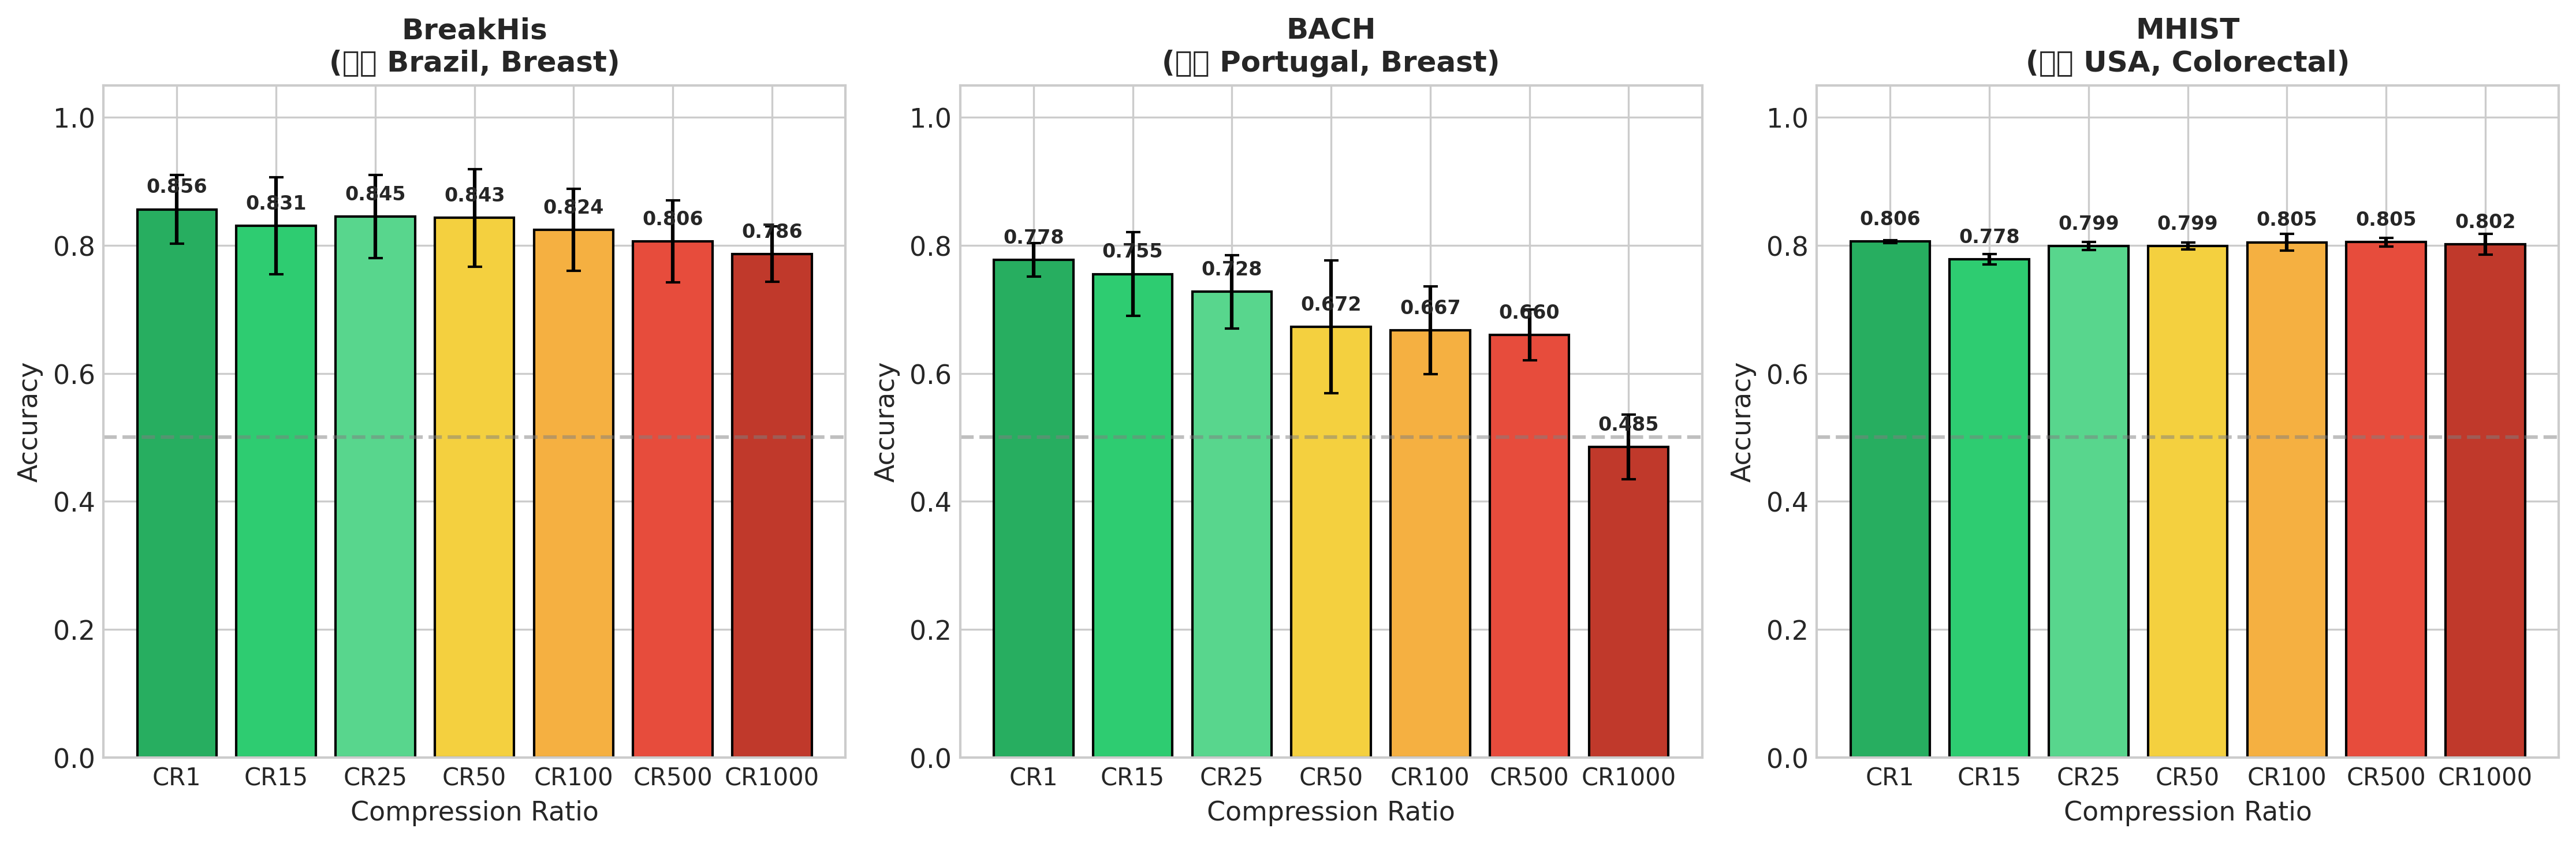

/tmp/ipykernel_6779/440609222.py:369: UserWarning: Glyph 127463 (\N{REGIONAL INDICATOR SYMBOL LETTER B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:369: UserWarning: Glyph 127479 (\N{REGIONAL INDICATOR SYMBOL LETTER R}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:369: UserWarning: Glyph 127477 (\N{REGIONAL INDICATOR SYMBOL LETTER P}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:369: UserWarning: Glyph 127481 (\N{REGIONAL INDICATOR SYMBOL LETTER T}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:369: UserWarning: Glyph 127482 (\N{REGIONAL INDICATOR SYMBOL LETTER U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_6779/440609222.py:369: UserWarning: Glyph 127480 (\N{REGIONAL INDICATOR SYMBOL LETTER S}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


✅ Figure 1 saved!

📊 GENERATING FIGURE 2: ROBUSTNESS VS COMPRESSION-AWARE


/tmp/ipykernel_6779/440609222.py:370: UserWarning: Glyph 127463 (\N{REGIONAL INDICATOR SYMBOL LETTER B}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{CONFIG['output_dir']}/figures/fig2_robustness_vs_cat.png", dpi=300, bbox_inches='tight')
/tmp/ipykernel_6779/440609222.py:370: UserWarning: Glyph 127479 (\N{REGIONAL INDICATOR SYMBOL LETTER R}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{CONFIG['output_dir']}/figures/fig2_robustness_vs_cat.png", dpi=300, bbox_inches='tight')
/tmp/ipykernel_6779/440609222.py:370: UserWarning: Glyph 127477 (\N{REGIONAL INDICATOR SYMBOL LETTER P}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{CONFIG['output_dir']}/figures/fig2_robustness_vs_cat.png", dpi=300, bbox_inches='tight')
/tmp/ipykernel_6779/440609222.py:370: UserWarning: Glyph 127481 (\N{REGIONAL INDICATOR SYMBOL LETTER T}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{CONFIG['output_dir']}/figures/fig2_robustness_vs_cat.png", dpi=300, bbox_inches='tight')
/tmp/ipykernel_6779/

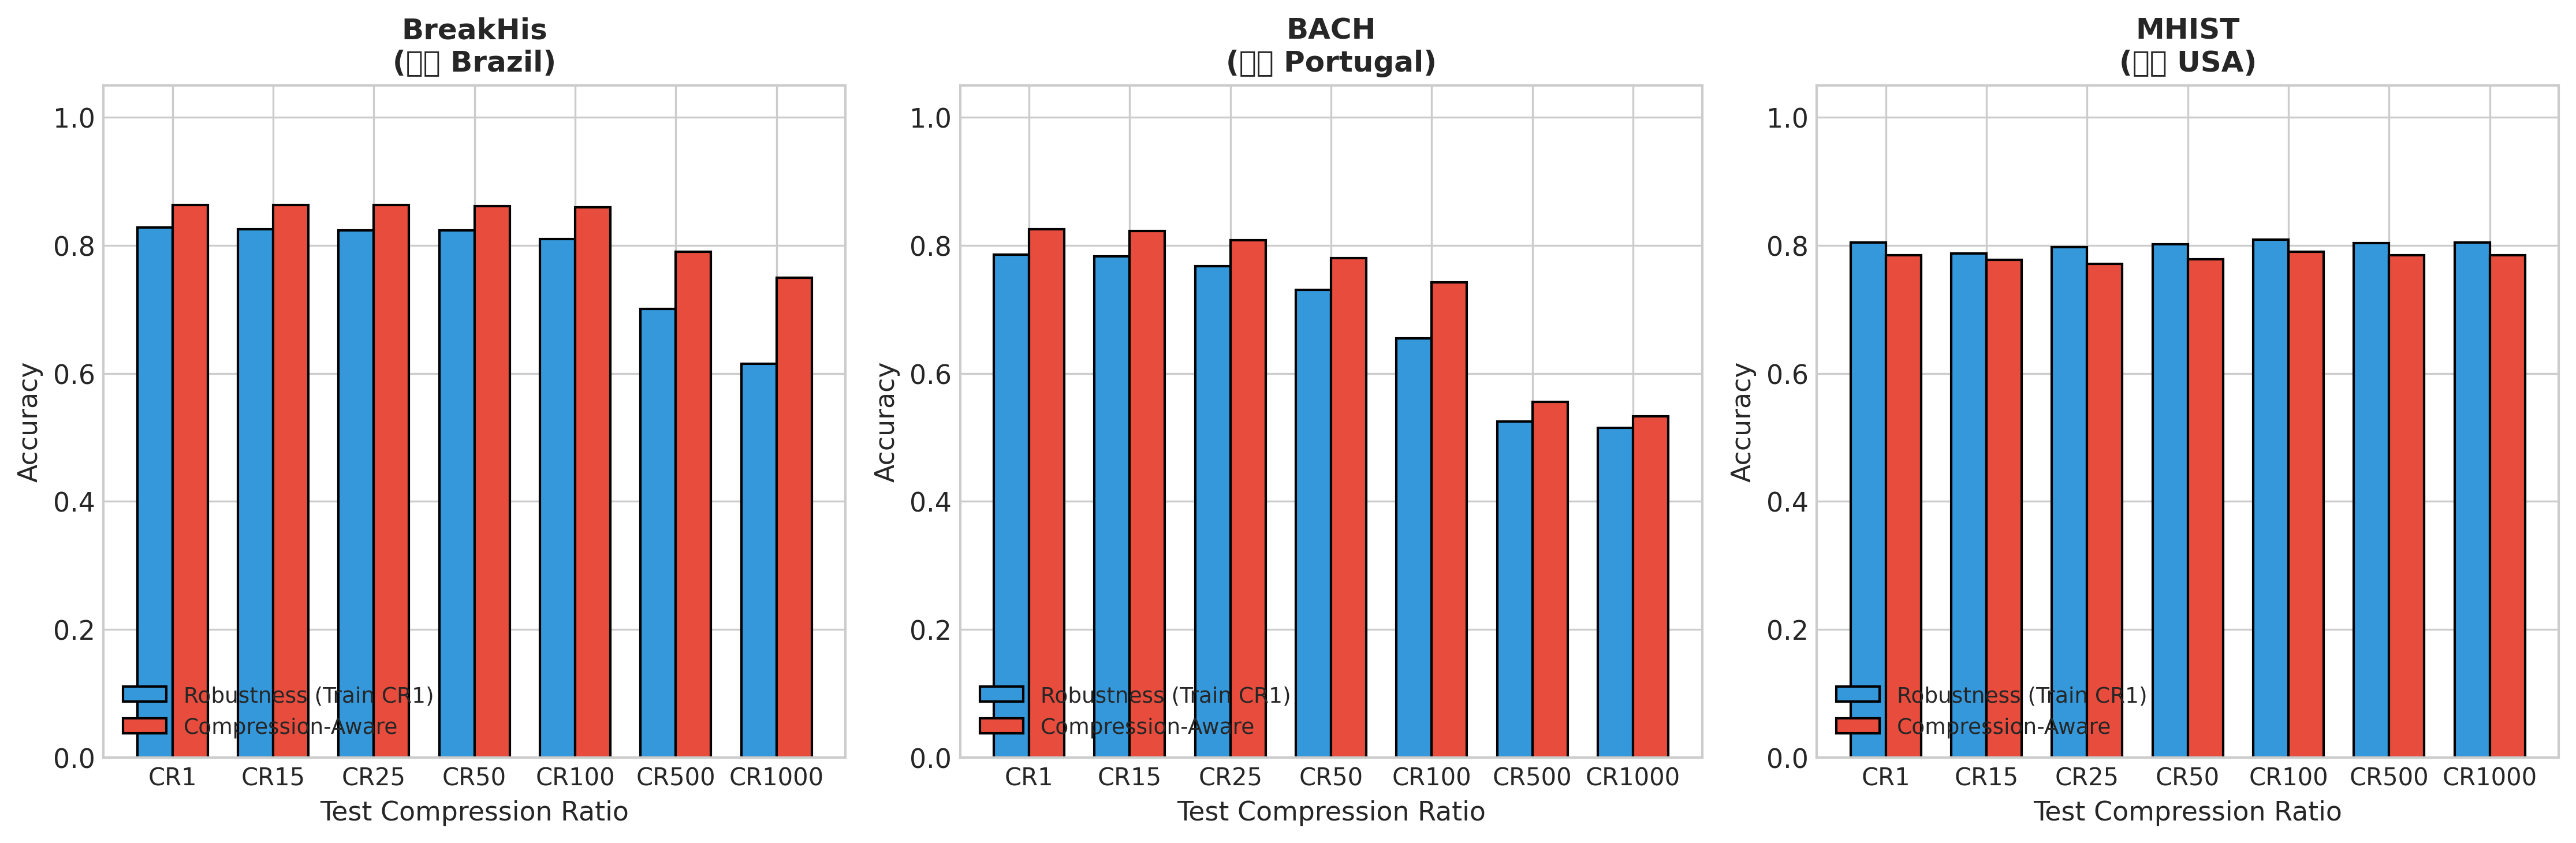

✅ Figure 2 saved!

📊 GENERATING FIGURE 3: CROSS-DATASET HEATMAP


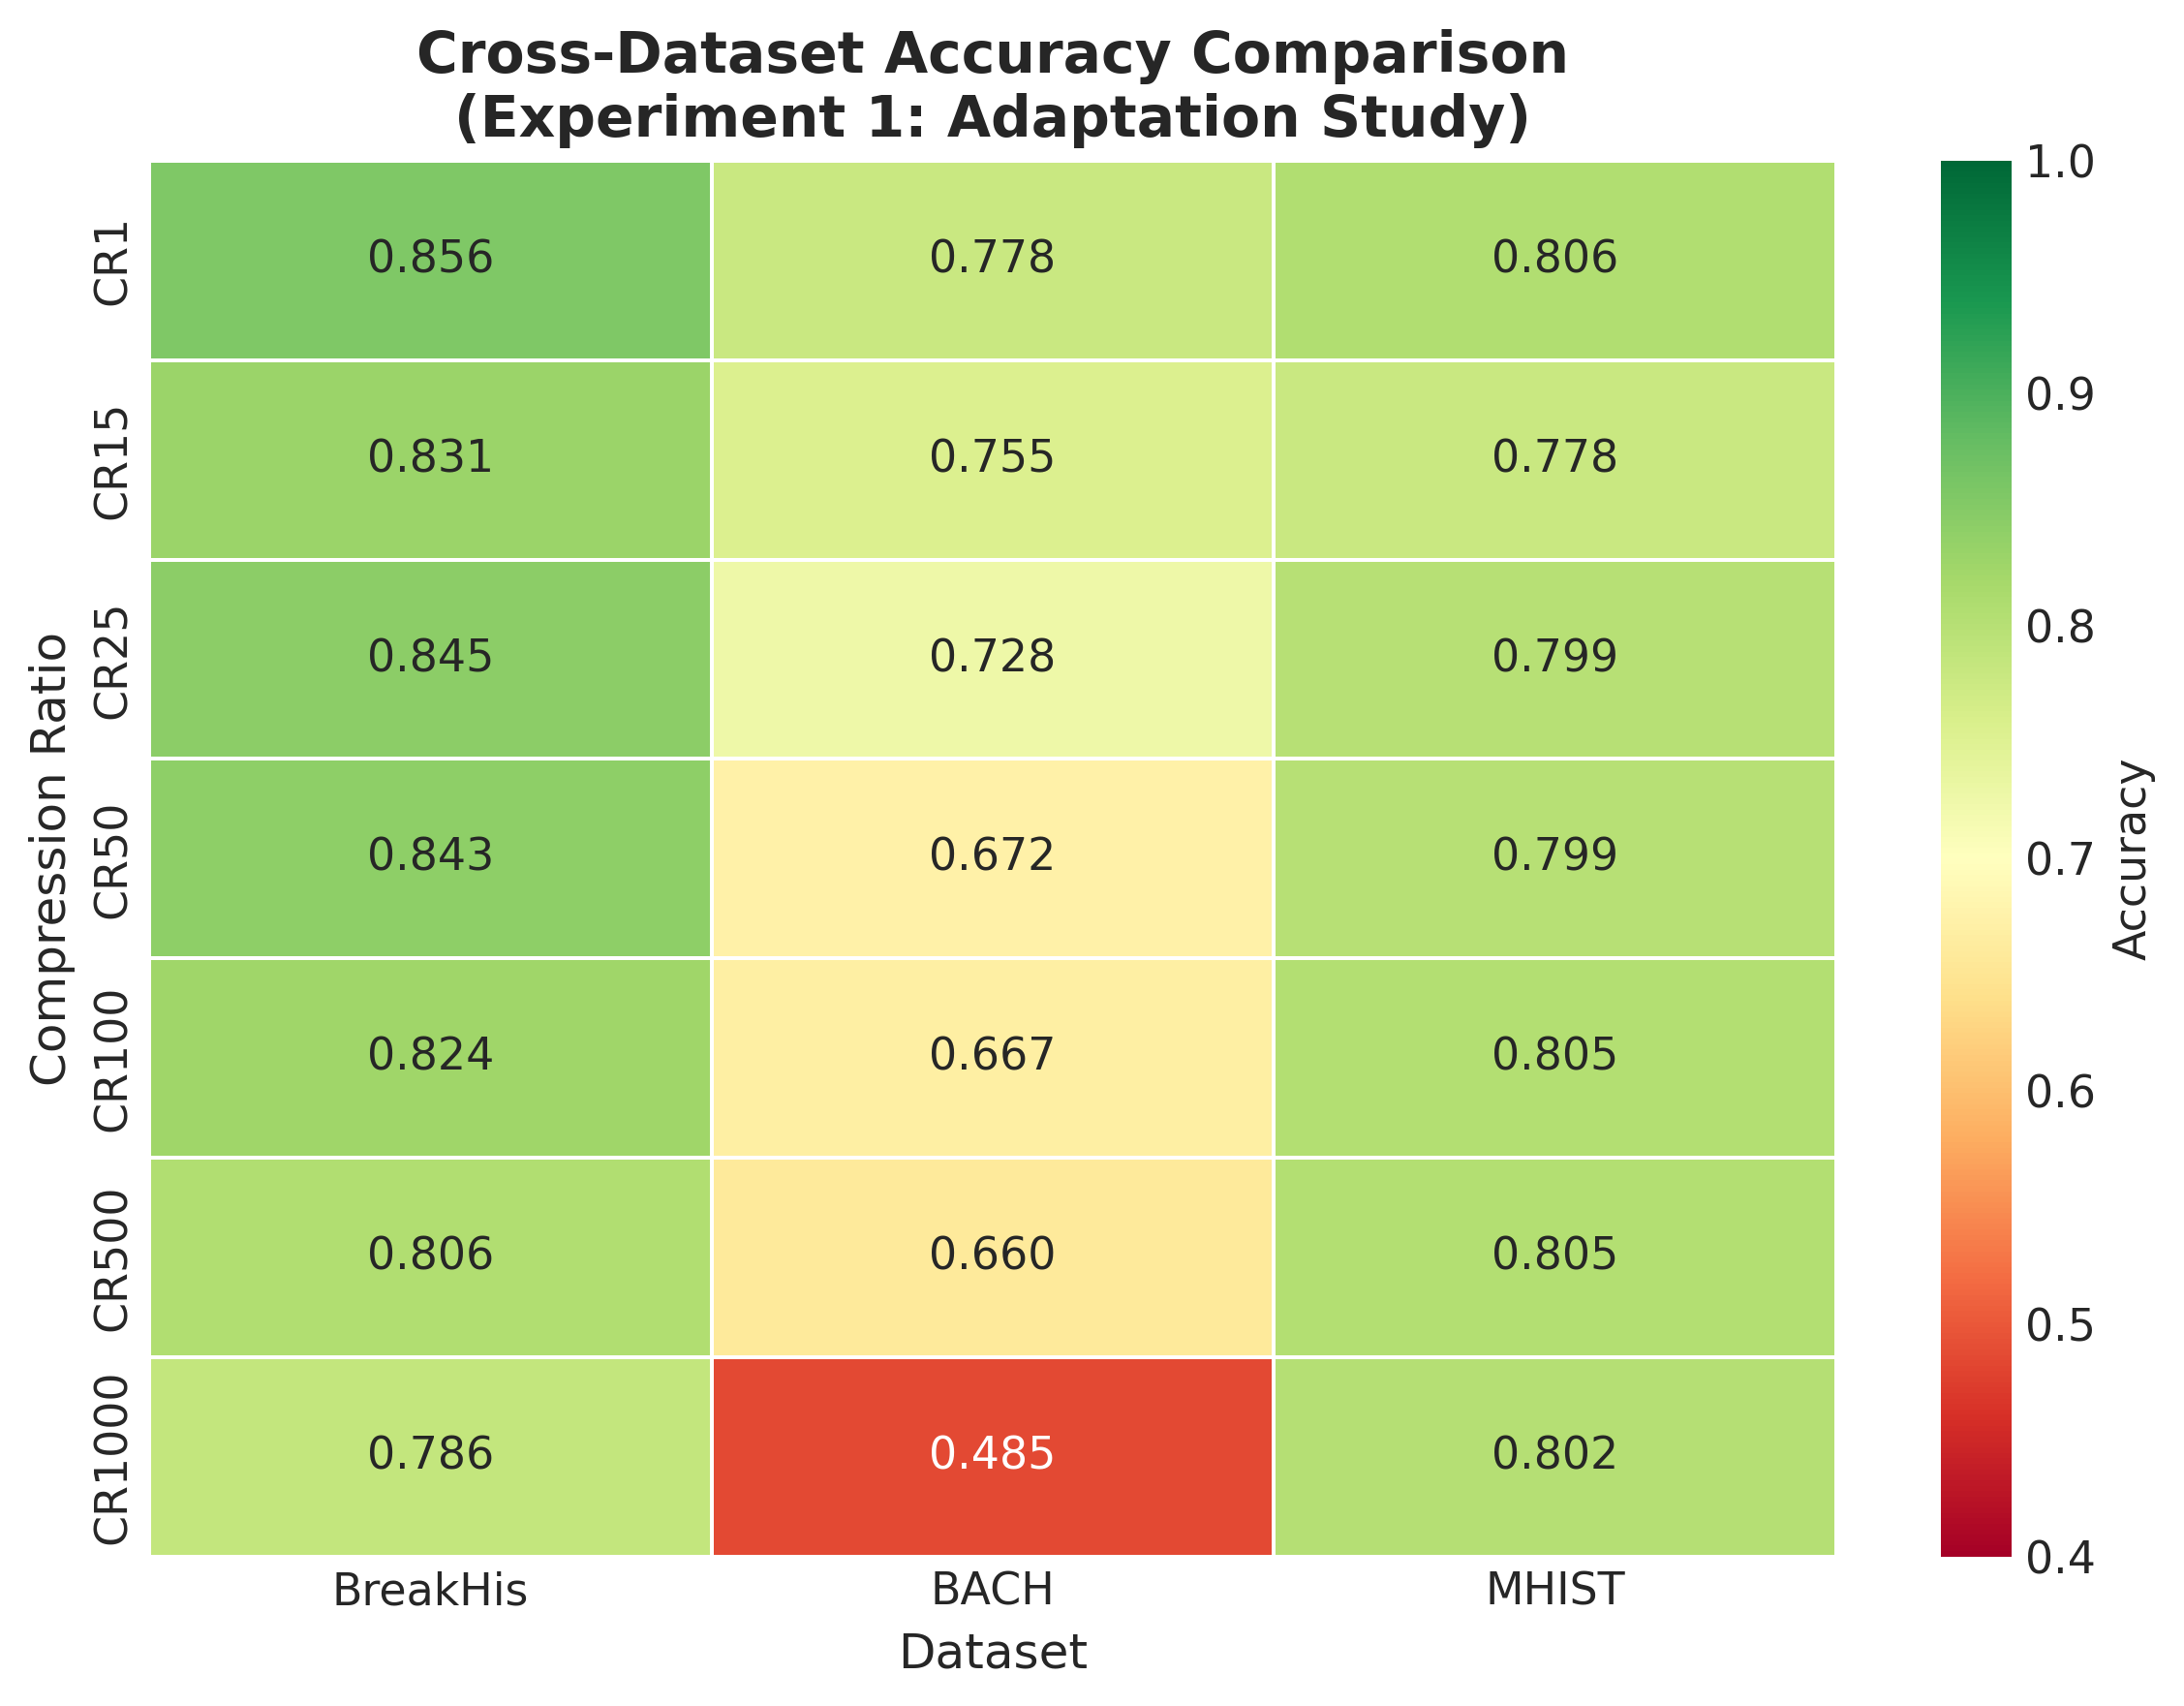

✅ Figure 3 saved!

📊 GENERATING FIGURE 4: CAT IMPROVEMENT


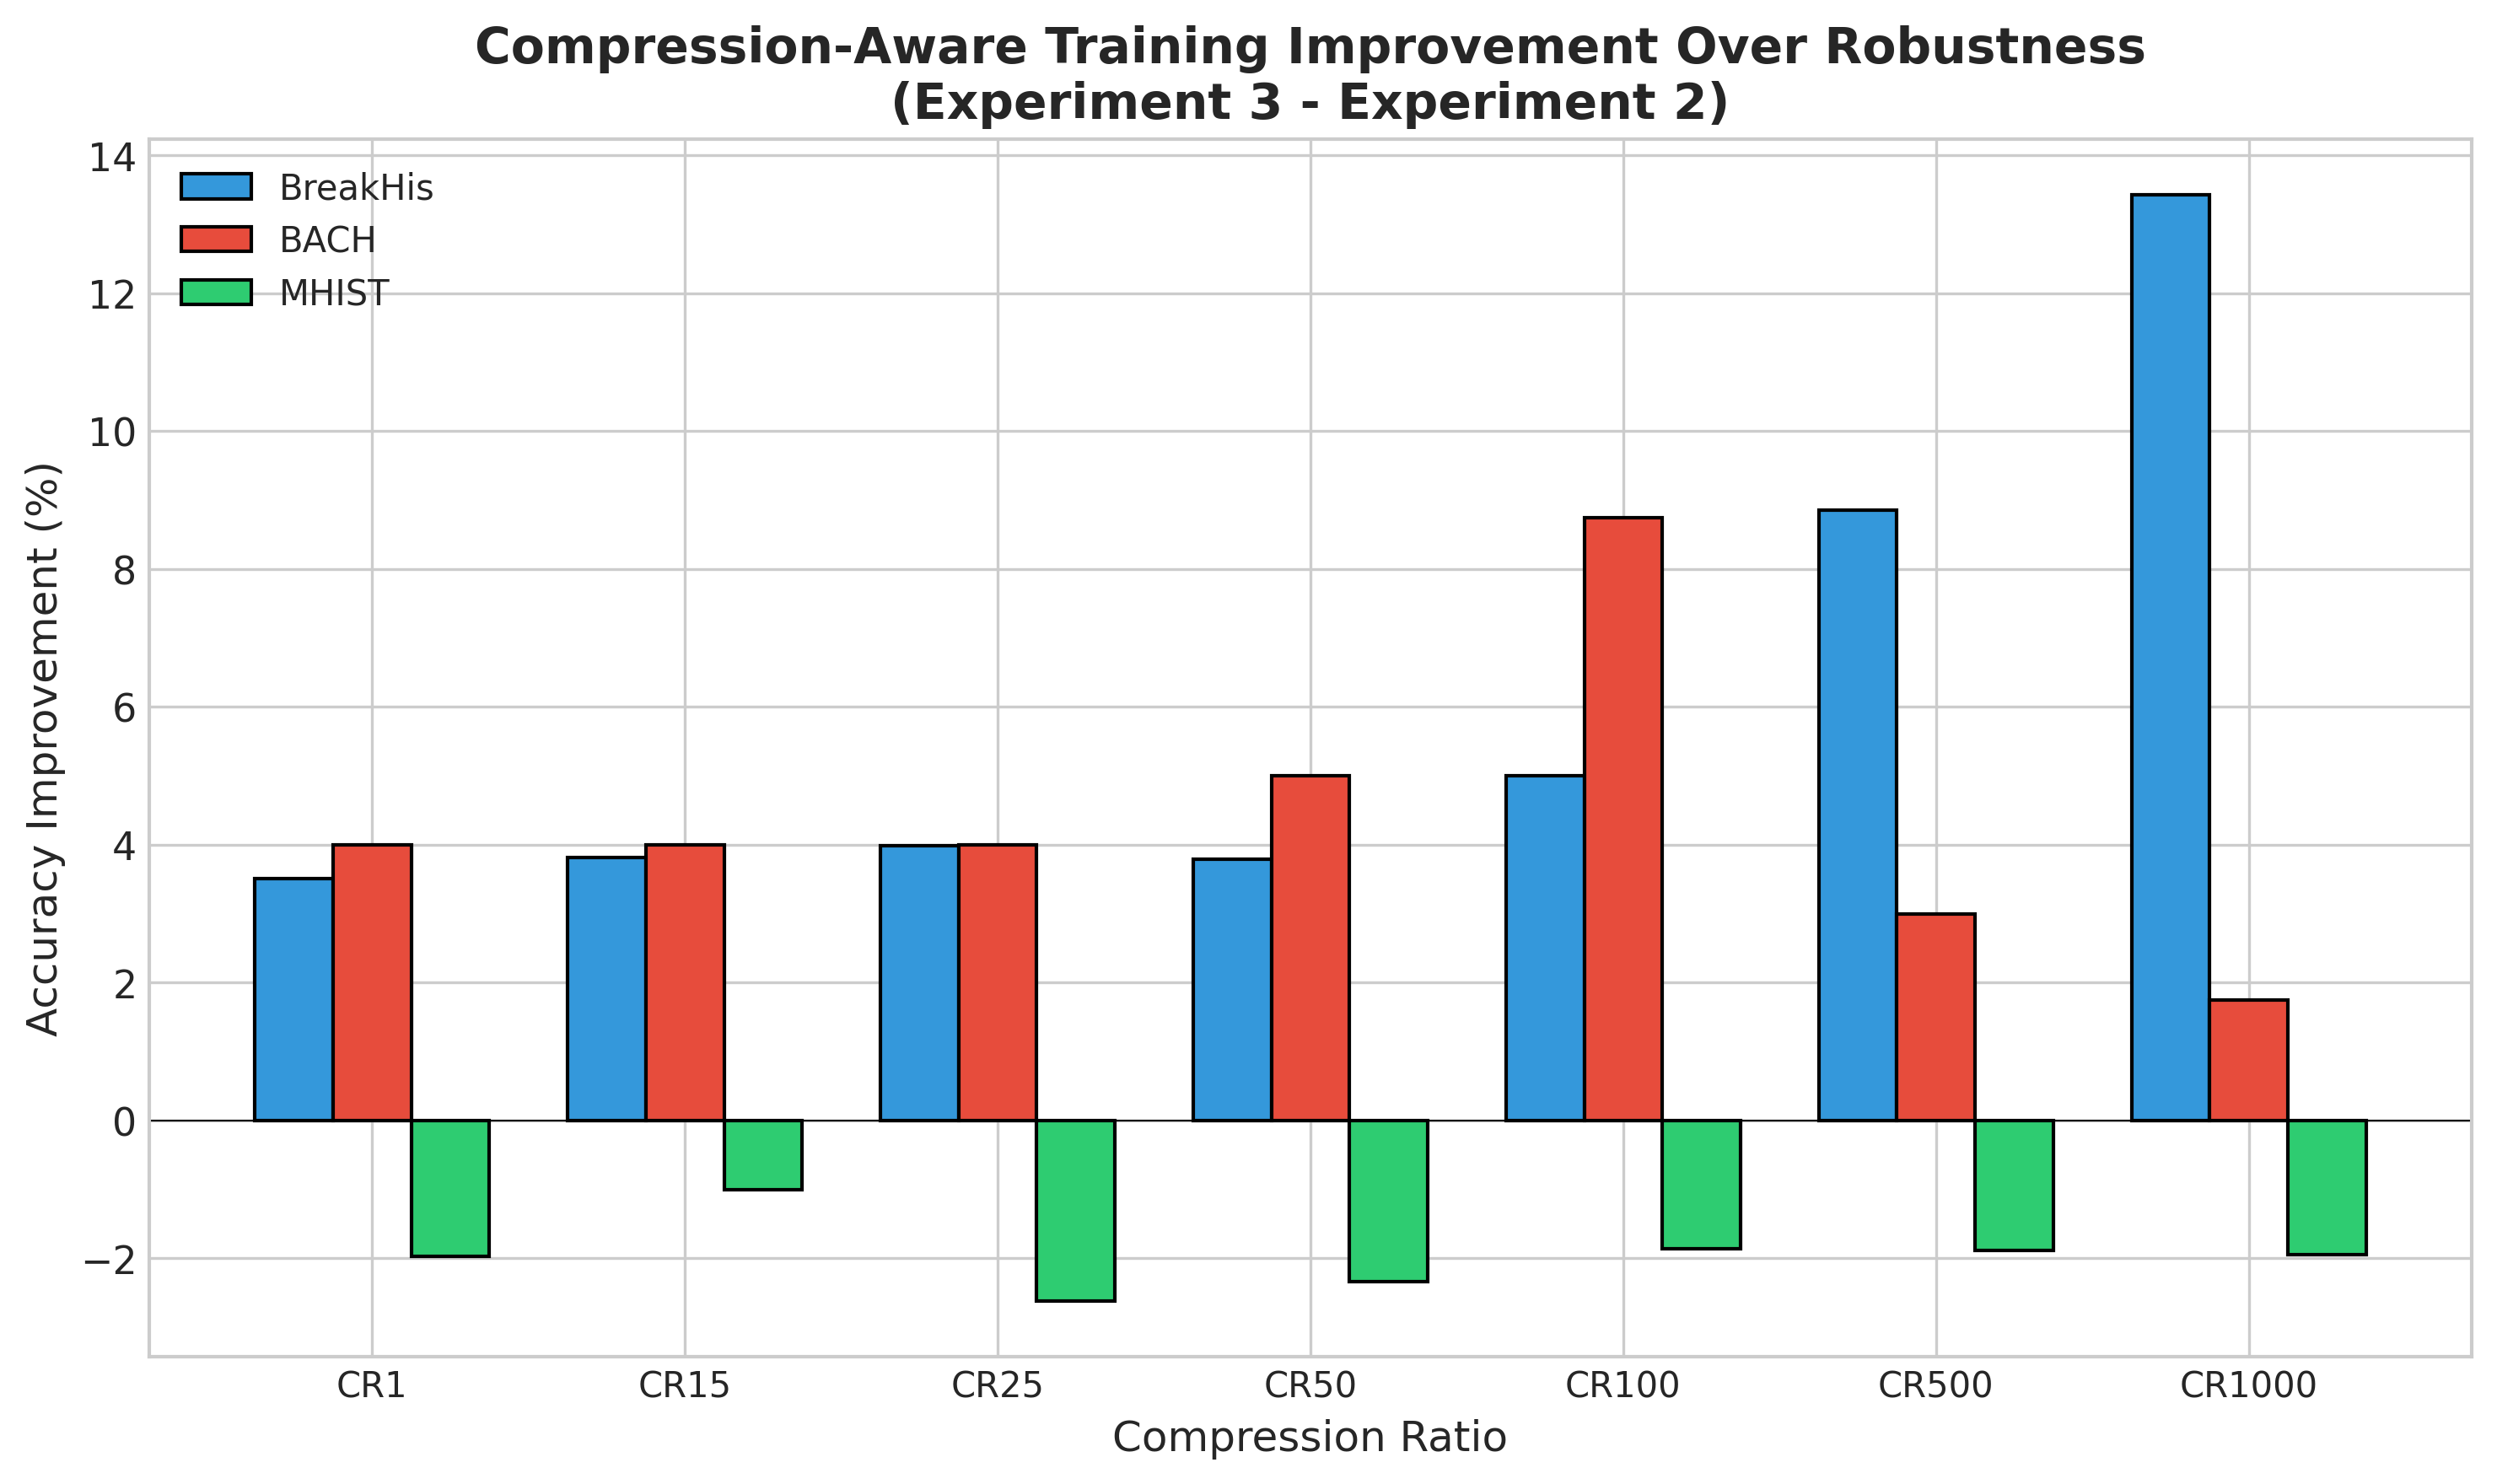

✅ Figure 4 saved!

📊 STATISTICAL ANALYSIS
 Dataset    Comparison Mean_Diff t_statistic p_value Cohens_d Significant
BreakHis  CR1 vs CR100    0.0318       1.874  0.1343    0.937          ns
BreakHis CR1 vs CR1000    0.0698       7.079  0.0021    3.540          **
    BACH  CR1 vs CR100    0.1100       3.029  0.0388    1.515           *
    BACH CR1 vs CR1000    0.2925      11.080  0.0004    5.540         ***
   MHIST  CR1 vs CR100    0.0010       0.152  0.8864    0.076          ns
   MHIST CR1 vs CR1000    0.0039       0.432  0.6879    0.216          ns

🎉 CROSS-DATASET ANALYSIS COMPLETE!

📁 ALL FILES SAVED TO: /content/drive/MyDrive/JPEG2000_Paper_Final

📋 TABLES GENERATED:
   ├── table1_dataset_characteristics.csv
   ├── table2_adaptation_results.csv
   ├── table3_robustness_vs_cat.csv
   ├── table4_key_findings.csv
   └── statistical_analysis.csv

📊 FIGURES GENERATED:
   ├── fig1_adaptation_all_datasets.png/pdf
   ├── fig2_robustness_vs_cat.png/pdf
   ├── fig3_heatmap.png/pdf
   └──

In [ ]:
# ============================================================================
# CROSS-DATASET ANALYSIS & FINAL FIGURES FOR PAPER
# ============================================================================
#
# Paper: "How Much Compression is Safe? Defining JPEG2000 Thresholds for
#        AI-Based Cancer Diagnosis in Breast and Colorectal Histopathology"
#
# Datasets: BreakHis (Brazil), BACH (Portugal), MHIST (USA)
# Target: PLOS ONE
#
# ============================================================================

# ============================================================================
# CELL 1: SETUP
# ============================================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 300

print("✅ Setup complete!")

# ============================================================================
# CELL 2: CONFIGURATION - UPDATE PATHS IF NEEDED
# ============================================================================

CONFIG = {
    'datasets': {
        'BreakHis': {
            'path': '/content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/results',
            'country': 'Brazil',
            'cancer': 'Breast',
            'images': 7909,
            'flag': '🇧🇷'
        },
        'BACH': {
            'path': '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_PLOS_ONE_FINAL/results',
            'country': 'Portugal',
            'cancer': 'Breast',
            'images': 400,
            'flag': '🇵🇹'
        },
        'MHIST': {
            'path': '/content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Results_Final/results',
            'country': 'USA',
            'cancer': 'Colorectal',
            'images': 3152,
            'flag': '🇺🇸'
        },
    },
    'output_dir': '/content/drive/MyDrive/JPEG2000_Paper_Final',
    'cr_levels': ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000'],
}

# Create output directory
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(f"{CONFIG['output_dir']}/figures", exist_ok=True)
os.makedirs(f"{CONFIG['output_dir']}/tables", exist_ok=True)

print("✅ Configuration loaded!")

# ============================================================================
# CELL 3: LOAD ALL RESULTS
# ============================================================================

print("=" * 70)
print("📊 LOADING RESULTS FROM ALL DATASETS")
print("=" * 70)

results = {}

for dataset_name, info in CONFIG['datasets'].items():
    print(f"\n📁 Loading {dataset_name}...")

    results[dataset_name] = {}

    # Try to load each experiment file
    for exp_name, filename in [
        ('exp1', 'experiment1_adaptation.csv'),
        ('exp2', 'experiment2_robustness.csv'),
        ('exp3', 'experiment3_compression_aware.csv'),
    ]:
        filepath = os.path.join(info['path'], filename)

        if os.path.exists(filepath):
            results[dataset_name][exp_name] = pd.read_csv(filepath)
            print(f"   ✅ {exp_name}: {len(results[dataset_name][exp_name])} rows")
        else:
            print(f"   ❌ {exp_name}: File not found - {filepath}")
            results[dataset_name][exp_name] = None

print("\n✅ Loading complete!")

# ============================================================================
# CELL 4: HELPER FUNCTIONS
# ============================================================================

def compute_95_ci(scores):
    """Compute mean and 95% confidence interval"""
    if len(scores) == 0:
        return 0, 0, (0, 0)
    mean = np.mean(scores)
    std = np.std(scores, ddof=1)
    ci = 1.96 * std / np.sqrt(len(scores))
    return mean, ci, (mean - ci, mean + ci)

def get_metric_summary(df, cr_level, metric='accuracy'):
    """Get mean ± CI for a metric at specific CR level"""
    if df is None:
        return None, None, None

    # Find the correct column name for compression ratio
    cr_col = None
    for col in ['cr_level', 'test_cr', 'compression_ratio', 'CR', 'Test_CR']:
        if col in df.columns:
            cr_col = col
            break

    if cr_col is None:
        return None, None, None

    cr_data = df[df[cr_col] == cr_level]
    if len(cr_data) == 0:
        return None, None, None
    return compute_95_ci(cr_data[metric].values)

def format_metric(mean, ci):
    """Format metric as string with CI"""
    if mean is None:
        return "N/A"
    return f"{mean:.4f} ± {ci:.4f}"

print("✅ Helper functions defined!")

# ============================================================================
# CELL 5: TABLE 1 - DATASET CHARACTERISTICS
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE 1: DATASET CHARACTERISTICS")
print("=" * 70)

table1_data = []
for dataset_name, info in CONFIG['datasets'].items():
    table1_data.append({
        'Dataset': dataset_name,
        'Country': info['country'],
        'Cancer Type': info['cancer'],
        'Images': info['images'],
        'Classes': 'Benign/Malignant',
        'Resolution': '224×224'
    })

table1 = pd.DataFrame(table1_data)
print(table1.to_string(index=False))

table1.to_csv(f"{CONFIG['output_dir']}/tables/table1_dataset_characteristics.csv", index=False)

# ============================================================================
# CELL 6: TABLE 2 - ADAPTATION RESULTS (ALL DATASETS)
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE 2: ADAPTATION STUDY RESULTS (Experiment 1)")
print("=" * 70)

table2_rows = []

for cr in CONFIG['cr_levels']:
    row = {'CR_Level': cr.replace('_original', '')}

    for dataset_name in CONFIG['datasets'].keys():
        exp1_df = results[dataset_name].get('exp1')
        mean, ci, _ = get_metric_summary(exp1_df, cr, 'accuracy')
        row[f'{dataset_name}_Acc'] = format_metric(mean, ci)
        row[f'{dataset_name}_Mean'] = mean if mean else 0

    table2_rows.append(row)

table2 = pd.DataFrame(table2_rows)
print(table2[[col for col in table2.columns if 'Mean' not in col]].to_string(index=False))

table2.to_csv(f"{CONFIG['output_dir']}/tables/table2_adaptation_results.csv", index=False)

# ============================================================================
# CELL 7: TABLE 3 - ROBUSTNESS VS COMPRESSION-AWARE
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE 3: ROBUSTNESS VS COMPRESSION-AWARE TRAINING")
print("=" * 70)

table3_rows = []

for cr in CONFIG['cr_levels']:
    row = {'CR_Level': cr.replace('_original', '')}

    for dataset_name in CONFIG['datasets'].keys():
        exp2_df = results[dataset_name].get('exp2')
        exp3_df = results[dataset_name].get('exp3')

        exp2_mean, exp2_ci, _ = get_metric_summary(exp2_df, cr, 'accuracy')
        exp3_mean, exp3_ci, _ = get_metric_summary(exp3_df, cr, 'accuracy')

        row[f'{dataset_name}_Robust'] = format_metric(exp2_mean, exp2_ci)
        row[f'{dataset_name}_CAT'] = format_metric(exp3_mean, exp3_ci)

        if exp2_mean and exp3_mean:
            improvement = (exp3_mean - exp2_mean) * 100
            row[f'{dataset_name}_Δ'] = f"{improvement:+.2f}%"
        else:
            row[f'{dataset_name}_Δ'] = "N/A"

    table3_rows.append(row)

table3 = pd.DataFrame(table3_rows)
print(table3.to_string(index=False))

table3.to_csv(f"{CONFIG['output_dir']}/tables/table3_robustness_vs_cat.csv", index=False)

# ============================================================================
# CELL 8: TABLE 4 - KEY FINDINGS SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("📋 TABLE 4: KEY FINDINGS SUMMARY")
print("=" * 70)

summary_rows = []

for dataset_name, info in CONFIG['datasets'].items():
    exp1_df = results[dataset_name].get('exp1')
    exp2_df = results[dataset_name].get('exp2')
    exp3_df = results[dataset_name].get('exp3')

    # Get accuracies at key CR levels
    cr1_mean, _, _ = get_metric_summary(exp1_df, 'CR1_original', 'accuracy')
    cr100_mean, _, _ = get_metric_summary(exp1_df, 'CR100', 'accuracy')
    cr1000_mean, _, _ = get_metric_summary(exp1_df, 'CR1000', 'accuracy')

    # Robustness at CR1000
    exp2_cr1000, _, _ = get_metric_summary(exp2_df, 'CR1000', 'accuracy')
    exp3_cr1000, _, _ = get_metric_summary(exp3_df, 'CR1000', 'accuracy')

    cat_improvement = ((exp3_cr1000 - exp2_cr1000) * 100) if exp2_cr1000 and exp3_cr1000 else 0

    summary_rows.append({
        'Dataset': dataset_name,
        'Country': info['flag'] + ' ' + info['country'],
        'Cancer': info['cancer'],
        'CR1_Acc': f"{cr1_mean:.4f}" if cr1_mean else "N/A",
        'CR100_Acc': f"{cr100_mean:.4f}" if cr100_mean else "N/A",
        'CR100_Drop': f"{(cr100_mean - cr1_mean) * 100:.2f}%" if cr1_mean and cr100_mean else "N/A",
        'CR1000_Acc': f"{cr1000_mean:.4f}" if cr1000_mean else "N/A",
        'CR1000_Drop': f"{(cr1000_mean - cr1_mean) * 100:.2f}%" if cr1_mean and cr1000_mean else "N/A",
        'CAT_Improvement': f"+{cat_improvement:.2f}%" if cat_improvement else "N/A"
    })

table4 = pd.DataFrame(summary_rows)
print(table4.to_string(index=False))

table4.to_csv(f"{CONFIG['output_dir']}/tables/table4_key_findings.csv", index=False)

# ============================================================================
# CELL 9: FIGURE 1 - ADAPTATION STUDY (ALL DATASETS)
# ============================================================================

print("\n" + "=" * 70)
print("📊 GENERATING FIGURE 1: ADAPTATION STUDY")
print("=" * 70)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors = ['#27ae60', '#2ecc71', '#58d68d', '#f4d03f', '#f5b041', '#e74c3c', '#c0392b']
cr_labels = [cr.replace('_original', '') for cr in CONFIG['cr_levels']]

for idx, (dataset_name, info) in enumerate(CONFIG['datasets'].items()):
    ax = axes[idx]

    exp1_df = results[dataset_name].get('exp1')

    if exp1_df is not None:
        means = []
        cis = []
        for cr in CONFIG['cr_levels']:
            mean, ci, _ = get_metric_summary(exp1_df, cr, 'accuracy')
            means.append(mean if mean else 0)
            cis.append(ci if ci else 0)

        bars = ax.bar(range(len(cr_labels)), means, color=colors, edgecolor='black', linewidth=1)
        ax.errorbar(range(len(cr_labels)), means, yerr=cis, fmt='none', color='black', capsize=3)

        # Add value labels
        for bar, mean in zip(bars, means):
            if mean > 0:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                       f'{mean:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

    ax.set_xticks(range(len(cr_labels)))
    ax.set_xticklabels(cr_labels, fontsize=10)
    ax.set_ylabel('Accuracy', fontsize=11)
    ax.set_xlabel('Compression Ratio', fontsize=11)
    ax.set_title(f'{dataset_name}\n({info["flag"]} {info["country"]}, {info["cancer"]})',
                 fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/figures/fig1_adaptation_all_datasets.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{CONFIG['output_dir']}/figures/fig1_adaptation_all_datasets.pdf", bbox_inches='tight')
plt.show()

print("✅ Figure 1 saved!")

# ============================================================================
# CELL 10: FIGURE 2 - ROBUSTNESS VS CAT (ALL DATASETS)
# ============================================================================

print("\n" + "=" * 70)
print("📊 GENERATING FIGURE 2: ROBUSTNESS VS COMPRESSION-AWARE")
print("=" * 70)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, (dataset_name, info) in enumerate(CONFIG['datasets'].items()):
    ax = axes[idx]

    exp2_df = results[dataset_name].get('exp2')
    exp3_df = results[dataset_name].get('exp3')

    x = np.arange(len(cr_labels))
    width = 0.35

    if exp2_df is not None and exp3_df is not None:
        exp2_means = []
        exp3_means = []

        for cr in CONFIG['cr_levels']:
            mean2, _, _ = get_metric_summary(exp2_df, cr, 'accuracy')
            mean3, _, _ = get_metric_summary(exp3_df, cr, 'accuracy')
            exp2_means.append(mean2 if mean2 else 0)
            exp3_means.append(mean3 if mean3 else 0)

        bars1 = ax.bar(x - width/2, exp2_means, width, label='Robustness (Train CR1)',
                       color='#3498db', edgecolor='black')
        bars2 = ax.bar(x + width/2, exp3_means, width, label='Compression-Aware',
                       color='#e74c3c', edgecolor='black')

    ax.set_xticks(x)
    ax.set_xticklabels(cr_labels, fontsize=10)
    ax.set_ylabel('Accuracy', fontsize=11)
    ax.set_xlabel('Test Compression Ratio', fontsize=11)
    ax.set_title(f'{dataset_name}\n({info["flag"]} {info["country"]})', fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/figures/fig2_robustness_vs_cat.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{CONFIG['output_dir']}/figures/fig2_robustness_vs_cat.pdf", bbox_inches='tight')
plt.show()

print("✅ Figure 2 saved!")

# ============================================================================
# CELL 11: FIGURE 3 - CROSS-DATASET COMPARISON HEATMAP
# ============================================================================

print("\n" + "=" * 70)
print("📊 GENERATING FIGURE 3: CROSS-DATASET HEATMAP")
print("=" * 70)

# Create heatmap data
heatmap_data = []

for cr in CONFIG['cr_levels']:
    row = []
    for dataset_name in CONFIG['datasets'].keys():
        exp1_df = results[dataset_name].get('exp1')
        mean, _, _ = get_metric_summary(exp1_df, cr, 'accuracy')
        row.append(mean if mean else 0)
    heatmap_data.append(row)

heatmap_df = pd.DataFrame(
    heatmap_data,
    index=[cr.replace('_original', '') for cr in CONFIG['cr_levels']],
    columns=list(CONFIG['datasets'].keys())
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(heatmap_df, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.4, vmax=1.0, ax=ax, linewidths=0.5,
            cbar_kws={'label': 'Accuracy'})

ax.set_xlabel('Dataset', fontsize=12)
ax.set_ylabel('Compression Ratio', fontsize=12)
ax.set_title('Cross-Dataset Accuracy Comparison\n(Experiment 1: Adaptation Study)',
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/figures/fig3_heatmap.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{CONFIG['output_dir']}/figures/fig3_heatmap.pdf", bbox_inches='tight')
plt.show()

print("✅ Figure 3 saved!")

# ============================================================================
# CELL 12: FIGURE 4 - COMPRESSION-AWARE IMPROVEMENT
# ============================================================================

print("\n" + "=" * 70)
print("📊 GENERATING FIGURE 4: CAT IMPROVEMENT")
print("=" * 70)

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(cr_labels))
width = 0.25
dataset_colors = ['#3498db', '#e74c3c', '#2ecc71']

for idx, (dataset_name, color) in enumerate(zip(CONFIG['datasets'].keys(), dataset_colors)):
    exp2_df = results[dataset_name].get('exp2')
    exp3_df = results[dataset_name].get('exp3')

    improvements = []
    for cr in CONFIG['cr_levels']:
        mean2, _, _ = get_metric_summary(exp2_df, cr, 'accuracy')
        mean3, _, _ = get_metric_summary(exp3_df, cr, 'accuracy')

        if mean2 and mean3:
            imp = (mean3 - mean2) * 100
        else:
            imp = 0
        improvements.append(imp)

    bars = ax.bar(x + idx * width, improvements, width, label=dataset_name, color=color, edgecolor='black')

ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.set_xticks(x + width)
ax.set_xticklabels(cr_labels, fontsize=10)
ax.set_ylabel('Accuracy Improvement (%)', fontsize=12)
ax.set_xlabel('Compression Ratio', fontsize=12)
ax.set_title('Compression-Aware Training Improvement Over Robustness\n(Experiment 3 - Experiment 2)',
             fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/figures/fig4_cat_improvement.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{CONFIG['output_dir']}/figures/fig4_cat_improvement.pdf", bbox_inches='tight')
plt.show()

print("✅ Figure 4 saved!")

# ============================================================================
# CELL 13: STATISTICAL ANALYSIS
# ============================================================================

print("\n" + "=" * 70)
print("📊 STATISTICAL ANALYSIS")
print("=" * 70)

# Paired t-tests: CR1 vs CR100, CR1 vs CR1000
stats_rows = []

for dataset_name in CONFIG['datasets'].keys():
    exp1_df = results[dataset_name].get('exp1')

    if exp1_df is not None:
        cr1_scores = exp1_df[exp1_df['cr_level'] == 'CR1_original']['accuracy'].values
        cr100_scores = exp1_df[exp1_df['cr_level'] == 'CR100']['accuracy'].values
        cr1000_scores = exp1_df[exp1_df['cr_level'] == 'CR1000']['accuracy'].values

        # CR1 vs CR100
        if len(cr1_scores) > 0 and len(cr100_scores) > 0:
            t_stat, p_value = stats.ttest_rel(cr1_scores, cr100_scores)
            diff = np.mean(cr1_scores) - np.mean(cr100_scores)
            cohens_d = diff / np.std(cr1_scores - cr100_scores) if np.std(cr1_scores - cr100_scores) > 0 else 0

            stats_rows.append({
                'Dataset': dataset_name,
                'Comparison': 'CR1 vs CR100',
                'Mean_Diff': f"{diff:.4f}",
                't_statistic': f"{t_stat:.3f}",
                'p_value': f"{p_value:.4f}",
                'Cohens_d': f"{cohens_d:.3f}",
                'Significant': '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
            })

        # CR1 vs CR1000
        if len(cr1_scores) > 0 and len(cr1000_scores) > 0:
            t_stat, p_value = stats.ttest_rel(cr1_scores, cr1000_scores)
            diff = np.mean(cr1_scores) - np.mean(cr1000_scores)
            cohens_d = diff / np.std(cr1_scores - cr1000_scores) if np.std(cr1_scores - cr1000_scores) > 0 else 0

            stats_rows.append({
                'Dataset': dataset_name,
                'Comparison': 'CR1 vs CR1000',
                'Mean_Diff': f"{diff:.4f}",
                't_statistic': f"{t_stat:.3f}",
                'p_value': f"{p_value:.4f}",
                'Cohens_d': f"{cohens_d:.3f}",
                'Significant': '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
            })

stats_df = pd.DataFrame(stats_rows)
print(stats_df.to_string(index=False))

stats_df.to_csv(f"{CONFIG['output_dir']}/tables/statistical_analysis.csv", index=False)

# ============================================================================
# CELL 14: FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("🎉 CROSS-DATASET ANALYSIS COMPLETE!")
print("=" * 70)

print(f"""
📁 ALL FILES SAVED TO: {CONFIG['output_dir']}

📋 TABLES GENERATED:
   ├── table1_dataset_characteristics.csv
   ├── table2_adaptation_results.csv
   ├── table3_robustness_vs_cat.csv
   ├── table4_key_findings.csv
   └── statistical_analysis.csv

📊 FIGURES GENERATED:
   ├── fig1_adaptation_all_datasets.png/pdf
   ├── fig2_robustness_vs_cat.png/pdf
   ├── fig3_heatmap.png/pdf
   └── fig4_cat_improvement.png/pdf

🔬 STUDY SUMMARY:
   • 3 Datasets: BreakHis (Brazil), BACH (Portugal), MHIST (USA)
   • 2 Cancer Types: Breast, Colorectal
   • ~11,500 total images
   • 7 Compression Ratios: CR1 to CR1000
   • 3 Experiments: Adaptation, Robustness, Compression-Aware

✅ READY FOR PAPER WRITING!
""")

# ============================================================================
# CELL 15: EXPORT FOR LATEX
# ============================================================================

print("\n" + "=" * 70)
print("📝 GENERATING LATEX TABLES")
print("=" * 70)

# Table 2 for LaTeX
latex_table2 = table2[[col for col in table2.columns if 'Mean' not in col]].to_latex(
    index=False,
    caption='Adaptation Study Results: Accuracy (Mean ± 95\\% CI) across compression ratios',
    label='tab:adaptation'
)

with open(f"{CONFIG['output_dir']}/tables/table2_adaptation.tex", 'w') as f:
    f.write(latex_table2)

# Table 4 for LaTeX
latex_table4 = table4.to_latex(
    index=False,
    caption='Key Findings Summary across datasets',
    label='tab:summary'
)

with open(f"{CONFIG['output_dir']}/tables/table4_summary.tex", 'w') as f:
    f.write(latex_table4)

print("✅ LaTeX tables saved!")
print(f"\n📁 Output directory: {CONFIG['output_dir']}")

In [ ]:
# ============================================================
# GENERATE: fig_noise_robustness_all_datasets & fig_breakhis_analysis
# Run in Google Colab with Google Drive mounted
# ============================================================

# ============================================================
# CELL 1: Setup
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from scipy import stats
import os
import warnings
warnings.filterwarnings('ignore')

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Paths
BASE_PATH = '/content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS'
OUTPUT_PATH = '/content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/final_figures_paper'
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['figure.dpi'] = 300

print("✅ Setup complete!")

# ============================================================
# CELL 2: Define Models and Colors
# ============================================================

MODELS = {
    'Phikon': {
        'nct': f'{BASE_PATH}/phikon_features.npz',
        'breakhis': f'{BASE_PATH}/phikon_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/phikon_pcam_features.npz',
        'mhist': f'{BASE_PATH}/phikon_mhist_features.npz',
        'color': '#2ecc71',
        'marker': 'o'
    },
    'UNI': {
        'nct': f'{BASE_PATH}/uni_verification_features.npz',  # CORRECT file
        'breakhis': f'{BASE_PATH}/uni_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/uni_pcam_features.npz',
        'mhist': f'{BASE_PATH}/uni_mhist_features.npz',
        'color': '#3498db',
        'marker': 's'
    },
    'GigaPath': {
        'nct': f'{BASE_PATH}/gigapath_features.npz',
        'breakhis': f'{BASE_PATH}/gigapath_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/gigapath_pcam_features.npz',
        'mhist': f'{BASE_PATH}/gigapath_mhist_features.npz',
        'color': '#9b59b6',
        'marker': '^'
    },
    'Virchow': {
        'nct': f'{BASE_PATH}/virchow_features.npz',
        'breakhis': f'{BASE_PATH}/virchow_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/virchow_pcam_features.npz',
        'mhist': f'{BASE_PATH}/virchow_mhist_features.npz',
        'color': '#e74c3c',
        'marker': 'D'
    },
    'CTransPath': {
        'nct': f'{BASE_PATH}/ctranspath_nct_features.npz',
        'breakhis': f'{BASE_PATH}/ctranspath_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/ctranspath_pcam_features.npz',
        'mhist': f'{BASE_PATH}/ctranspath_mhist_features.npz',
        'color': '#f39c12',
        'marker': 'v'
    },
    'ViT-B-ImageNet': {
        'nct': f'{BASE_PATH}/vit_imagenet_features.npz',
        'breakhis': f'{BASE_PATH}/vit_imagenet_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/vit_imagenet_pcam_features.npz',
        'mhist': f'{BASE_PATH}/vit_imagenet_mhist_features.npz',
        'color': '#1abc9c',
        'marker': 'p'
    },
    'ResNet50-ImageNet': {
        'nct': f'{BASE_PATH}/resnet50_features.npz',
        'breakhis': f'{BASE_PATH}/resnet50_breakhis_features.npz',
        'pcam': f'{BASE_PATH}/resnet50_pcam_features.npz',
        'mhist': f'{BASE_PATH}/resnet50_mhist_features.npz',
        'color': '#34495e',
        'marker': 'h'
    }
}

def load_features(path):
    """Load features from npz file with flexible key handling"""
    if not os.path.exists(path):
        print(f"  ⚠️ Not found: {path}")
        return None, None, None, None

    data = np.load(path)
    keys = list(data.keys())

    # Try different key naming conventions
    if 'X_train' in data:
        return data['X_train'], data['y_train'], data['X_test'], data['y_test']
    elif 'train_features' in data:
        return data['train_features'], data['train_labels'], data['test_features'], data['test_labels']
    elif 'features' in data and 'labels' in data:
        # Single array - need to split
        X, y = data['features'], data['labels']
        from sklearn.model_selection import train_test_split
        return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    else:
        print(f"  Keys found: {keys}")
        return None, None, None, None

print("✅ Models defined!")

# ============================================================
# CELL 3: FIGURE 1 - Noise Robustness All Datasets (FROM REAL DATA)
# ============================================================

print("\n" + "="*70)
print("GENERATING: fig_noise_robustness_all_datasets")
print("="*70)

# We'll compute noise robustness by adding Gaussian noise to features
# and measuring accuracy degradation

sigma_levels = [0.0, 0.25, 0.5, 0.75, 1.0]

def evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels):
    """Train classifier and evaluate at different noise levels"""
    # Train on clean data
    clf = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
    clf.fit(X_train, y_train)

    accuracies = []
    for sigma in sigma_levels:
        if sigma == 0:
            X_noisy = X_test
        else:
            # Add Gaussian noise
            noise = np.random.randn(*X_test.shape) * sigma
            X_noisy = X_test + noise

        y_pred = clf.predict(X_noisy)
        acc = accuracy_score(y_test, y_pred) * 100
        accuracies.append(acc)

    return accuracies

# Store results for all datasets
noise_results = {
    'NCT-CRC': {},
    'BreakHis': {},
    'PCam': {},
    'MHIST': {}
}

# Process each model and dataset
for model_name, config in MODELS.items():
    print(f"\n--- {model_name} ---")

    # NCT-CRC
    print("  Loading NCT-CRC...")
    X_train, y_train, X_test, y_test = load_features(config['nct'])
    if X_train is not None:
        accs = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['NCT-CRC'][model_name] = accs
        print(f"    NCT-CRC: {accs[0]:.1f}% → {accs[-1]:.1f}% (drop: {accs[0]-accs[-1]:.1f} pp)")

    # BreakHis
    print("  Loading BreakHis...")
    X_train, y_train, X_test, y_test = load_features(config['breakhis'])
    if X_train is not None:
        accs = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['BreakHis'][model_name] = accs
        print(f"    BreakHis: {accs[0]:.1f}% → {accs[-1]:.1f}%")

    # PCam
    print("  Loading PCam...")
    X_train, y_train, X_test, y_test = load_features(config['pcam'])
    if X_train is not None:
        accs = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['PCam'][model_name] = accs
        print(f"    PCam: {accs[0]:.1f}% → {accs[-1]:.1f}%")

    # MHIST
    print("  Loading MHIST...")
    X_train, y_train, X_test, y_test = load_features(config['mhist'])
    if X_train is not None:
        accs = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['MHIST'][model_name] = accs
        print(f"    MHIST: {accs[0]:.1f}% → {accs[-1]:.1f}%")

print("\n✅ Noise robustness evaluation complete!")

# ============================================================
# CELL 4: Plot Noise Robustness Figure
# ============================================================

print("\n📊 Creating noise robustness figure...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

datasets = ['NCT-CRC', 'BreakHis', 'PCam', 'MHIST']
panel_labels = ['(A)', '(B)', '(C)', '(D)']

for idx, (dataset, ax) in enumerate(zip(datasets, axes)):
    if dataset in noise_results and len(noise_results[dataset]) > 0:
        for model_name, config in MODELS.items():
            if model_name in noise_results[dataset]:
                accs = noise_results[dataset][model_name]
                ax.plot(sigma_levels, accs,
                       marker=config['marker'],
                       color=config['color'],
                       linewidth=2.5,
                       markersize=8,
                       label=model_name.replace('-ImageNet', '-IN'))

        ax.set_xlabel('Noise Level (σ)', fontsize=12, fontweight='bold')
        ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
        ax.set_title(f'{panel_labels[idx]} {dataset}', fontsize=13, fontweight='bold')

        # Set y-axis based on dataset
        if dataset == 'NCT-CRC':
            ax.set_ylim(0, 105)
            ax.axhline(y=11.1, color='red', linestyle=':', alpha=0.5, linewidth=1.5)
            ax.text(0.02, 14, 'Random (11.1%)', fontsize=9, color='red')
        else:
            ax.set_ylim(40, 100)
            ax.axhline(y=50, color='red', linestyle=':', alpha=0.5, linewidth=1.5)

        # Add tier shading for NCT-CRC
        if dataset == 'NCT-CRC':
            ax.axhspan(90, 105, alpha=0.08, color='green')
            ax.axhspan(45, 65, alpha=0.08, color='orange')
            ax.axhspan(0, 35, alpha=0.08, color='red')

        ax.grid(True, alpha=0.3)
        ax.legend(loc='lower left', fontsize=8, ncol=2)

plt.suptitle('Noise Robustness Across Four Histopathology Datasets\nThree-Tier Hierarchy: Global ViT > Swin > CNN',
            fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(f'{OUTPUT_PATH}/fig_noise_robustness_all_datasets.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_PATH}/fig_noise_robustness_all_datasets.pdf', bbox_inches='tight')
plt.show()

print(f"✅ Saved: {OUTPUT_PATH}/fig_noise_robustness_all_datasets.png")

# ============================================================
# CELL 5: Summary Bar Chart at σ=1.0
# ============================================================

print("\n📊 Creating summary bar chart at σ=1.0...")

fig, ax = plt.subplots(figsize=(14, 6))

model_names = list(MODELS.keys())
model_names_short = [m.replace('-ImageNet', '-IN') for m in model_names]
x = np.arange(len(model_names))
width = 0.2

dataset_colors = {'NCT-CRC': '#3498db', 'BreakHis': '#e74c3c', 'PCam': '#2ecc71', 'MHIST': '#9b59b6'}

for i, dataset in enumerate(datasets):
    if dataset in noise_results:
        accs_at_sigma1 = []
        for model in model_names:
            if model in noise_results[dataset]:
                accs_at_sigma1.append(noise_results[dataset][model][-1])  # σ=1.0
            else:
                accs_at_sigma1.append(0)

        bars = ax.bar(x + i*width, accs_at_sigma1, width,
                     label=dataset, color=dataset_colors[dataset],
                     alpha=0.85, edgecolor='white')

ax.set_xlabel('Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy at σ=1.0 (%)', fontsize=12, fontweight='bold')
ax.set_title('Noise Robustness Summary: Accuracy at Maximum Perturbation (σ=1.0)',
            fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x + 1.5*width)
ax.set_xticklabels(model_names_short, fontsize=10, rotation=45, ha='right')
ax.set_ylim(0, 110)
ax.legend(loc='upper right', fontsize=10)
ax.axhline(y=50, color='gray', linestyle='--', alpha=0.3)

# Add tier annotations
ax.axvspan(-0.5, 4.5, alpha=0.05, color='green')  # FMs + ViT-B
ax.axvspan(4.5, 5.5, alpha=0.05, color='orange')  # CTransPath
ax.axvspan(5.5, 6.5, alpha=0.05, color='red')     # ResNet50

plt.tight_layout()
plt.savefig(f'{OUTPUT_PATH}/fig_noise_robustness_summary_sigma1.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_PATH}/fig_noise_robustness_summary_sigma1.pdf', bbox_inches='tight')
plt.show()

print(f"✅ Saved: {OUTPUT_PATH}/fig_noise_robustness_summary_sigma1.png")

# ============================================================
# CELL 6: FIGURE 2 - BreakHis Analysis (FROM REAL DATA)
# ============================================================

print("\n" + "="*70)
print("GENERATING: fig_breakhis_analysis")
print("="*70)

# Load BreakHis data for detailed analysis
breakhis_results = {}

for model_name, config in MODELS.items():
    print(f"\n--- {model_name} ---")

    X_train, y_train, X_test, y_test = load_features(config['breakhis'])

    if X_train is not None:
        # Train classifier
        clf = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
        clf.fit(X_train, y_train)

        # Predictions
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)

        # Metrics
        acc = accuracy_score(y_test, y_pred) * 100

        # Per-class accuracy (binary: benign=0, malignant=1)
        benign_mask = y_test == 0
        malignant_mask = y_test == 1

        benign_acc = accuracy_score(y_test[benign_mask], y_pred[benign_mask]) * 100 if benign_mask.sum() > 0 else 0
        malignant_acc = accuracy_score(y_test[malignant_mask], y_pred[malignant_mask]) * 100 if malignant_mask.sum() > 0 else 0

        breakhis_results[model_name] = {
            'accuracy': acc,
            'benign_acc': benign_acc,
            'malignant_acc': malignant_acc,
            'y_test': y_test,
            'y_pred': y_pred,
            'y_prob': y_prob
        }

        print(f"  Accuracy: {acc:.2f}%")
        print(f"  Benign: {benign_acc:.2f}%, Malignant: {malignant_acc:.2f}%")

print("\n✅ BreakHis analysis complete!")

# ============================================================
# CELL 7: Plot BreakHis Analysis Figure
# ============================================================

print("\n📊 Creating BreakHis analysis figure...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel A: Overall accuracy comparison
ax1 = axes[0, 0]
model_names = list(breakhis_results.keys())
model_names_short = [m.replace('-ImageNet', '-IN') for m in model_names]
accuracies = [breakhis_results[m]['accuracy'] for m in model_names]
colors = [MODELS[m]['color'] for m in model_names]

bars = ax1.bar(model_names_short, accuracies, color=colors, edgecolor='white', linewidth=0.5)

# Highlight ResNet50 (best performer)
for i, (bar, acc) in enumerate(zip(bars, accuracies)):
    if 'ResNet50' in model_names[i]:
        bar.set_edgecolor('gold')
        bar.set_linewidth(3)
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{acc:.1f}%',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_xlabel('Model', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax1.set_title('(A) BreakHis Classification Accuracy\nResNet50-ImageNet Outperforms All FMs',
             fontsize=12, fontweight='bold')
ax1.set_ylim(75, 92)
ax1.axhline(y=max(accuracies), color='gold', linestyle='--', alpha=0.5, linewidth=2)
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')

# Panel B: Per-class accuracy (Benign vs Malignant)
ax2 = axes[0, 1]
x = np.arange(len(model_names))
width = 0.35

benign_accs = [breakhis_results[m]['benign_acc'] for m in model_names]
malignant_accs = [breakhis_results[m]['malignant_acc'] for m in model_names]

bars1 = ax2.bar(x - width/2, benign_accs, width, label='Benign', color='#3498db', alpha=0.85)
bars2 = ax2.bar(x + width/2, malignant_accs, width, label='Malignant', color='#e74c3c', alpha=0.85)

ax2.set_xlabel('Model', fontsize=12, fontweight='bold')
ax2.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax2.set_title('(B) Per-Class Accuracy: Benign vs Malignant', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(model_names_short, rotation=45, ha='right')
ax2.set_ylim(70, 100)
ax2.legend(loc='lower right')

# Panel C: FM Advantage comparison across datasets
ax3 = axes[1, 0]

# Verified data from experiments
datasets_compare = ['NCT-CRC', 'PCam', 'MHIST', 'BreakHis']
fm_best = [99.86, 91.65, 81.58, 86.54]  # Best FM accuracy
resnet_acc = [96.87, 80.07, 78.51, 87.09]  # ResNet50 accuracy
fm_advantage = [fm - res for fm, res in zip(fm_best, resnet_acc)]

colors_adv = ['#2ecc71' if adv > 0 else '#e74c3c' for adv in fm_advantage]
bars = ax3.bar(datasets_compare, fm_advantage, color=colors_adv, edgecolor='white', alpha=0.85)

for bar, adv in zip(bars, fm_advantage):
    ypos = bar.get_height() + 0.2 if adv > 0 else bar.get_height() - 0.5
    ax3.text(bar.get_x() + bar.get_width()/2, ypos, f'{adv:+.1f} pp',
            ha='center', va='bottom' if adv > 0 else 'top',
            fontsize=11, fontweight='bold')

ax3.set_xlabel('Dataset', fontsize=12, fontweight='bold')
ax3.set_ylabel('FM Advantage over ResNet50 (pp)', fontsize=12, fontweight='bold')
ax3.set_title('(C) Foundation Model Advantage by Dataset\nBreakHis Shows NEGATIVE Advantage',
             fontsize=12, fontweight='bold')
ax3.axhline(y=0, color='black', linewidth=1.5)
ax3.set_ylim(-3, 14)

# Highlight BreakHis anomaly
ax3.annotate('Anomaly!\nResNet50 wins', xy=(3, -0.55), xytext=(2.5, -2),
            fontsize=10, fontweight='bold', color='darkred',
            arrowprops=dict(arrowstyle='->', color='darkred', lw=2))

# Panel D: Hypothesis - Magnification effect
ax4 = axes[1, 1]

# Magnification levels and FM advantage
magnifications = ['10X\n(PCam)', '20X\n(NCT-CRC)', '20X\n(MHIST)', '100X\n(BreakHis)']
fm_adv_by_mag = [11.58, 2.99, 3.07, -0.55]
mag_values = [10, 20, 20, 100]

# Scatter plot with trend
ax4.scatter(mag_values, fm_adv_by_mag, s=200, c=['#2ecc71', '#2ecc71', '#2ecc71', '#e74c3c'],
           edgecolors='black', linewidth=2, zorder=5)

for mag, adv, label in zip(mag_values, fm_adv_by_mag, magnifications):
    offset = (5, 5) if adv > 0 else (5, -15)
    ax4.annotate(label.replace('\n', ' '), (mag, adv), xytext=offset,
                textcoords='offset points', fontsize=10, fontweight='bold')

# Trend line
z = np.polyfit(mag_values, fm_adv_by_mag, 1)
p = np.poly1d(z)
x_trend = np.linspace(5, 110, 100)
ax4.plot(x_trend, p(x_trend), 'r--', linewidth=2, alpha=0.7, label='Trend')

ax4.set_xlabel('Magnification Level (X)', fontsize=12, fontweight='bold')
ax4.set_ylabel('FM Advantage (pp)', fontsize=12, fontweight='bold')
ax4.set_title('(D) Hypothesis: Magnification Effect\nHigher Magnification → Lower FM Advantage',
             fontsize=12, fontweight='bold')
ax4.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax4.set_xlim(0, 120)
ax4.set_ylim(-3, 14)

# Add correlation
r, p_val = stats.pearsonr(mag_values, fm_adv_by_mag)
ax4.text(0.95, 0.95, f'r = {r:.2f}', transform=ax4.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle('The BreakHis Anomaly: Why ResNet50-ImageNet Outperforms Foundation Models',
            fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(f'{OUTPUT_PATH}/fig_breakhis_analysis.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_PATH}/fig_breakhis_analysis.pdf', bbox_inches='tight')
plt.show()

print(f"✅ Saved: {OUTPUT_PATH}/fig_breakhis_analysis.png")

# ============================================================
# CELL 8: Print Summary Statistics
# ============================================================

print("\n" + "="*70)
print("SUMMARY: NOISE ROBUSTNESS AT σ=1.0")
print("="*70)

print("\n| Model | NCT-CRC | BreakHis | PCam | MHIST |")
print("|-------|---------|----------|------|-------|")
for model in model_names:
    row = f"| {model.replace('-ImageNet', '-IN'):15} |"
    for dataset in datasets:
        if model in noise_results.get(dataset, {}):
            acc = noise_results[dataset][model][-1]
            row += f" {acc:6.1f}% |"
        else:
            row += "    N/A |"
    print(row)

print("\n" + "="*70)
print("SUMMARY: BREAKHIS ACCURACY")
print("="*70)

print("\n| Model | Overall | Benign | Malignant |")
print("|-------|---------|--------|-----------|")
for model in breakhis_results:
    r = breakhis_results[model]
    print(f"| {model.replace('-ImageNet', '-IN'):15} | {r['accuracy']:6.2f}% | {r['benign_acc']:5.1f}% | {r['malignant_acc']:8.1f}% |")

print("\n" + "="*70)
print("✅ ALL FIGURES GENERATED!")
print("="*70)
print(f"\nOutput directory: {OUTPUT_PATH}")
print("\nGenerated files:")
print("  1. fig_noise_robustness_all_datasets.png/pdf")
print("  2. fig_noise_robustness_summary_sigma1.png/pdf")
print("  3. fig_breakhis_analysis.png/pdf")

Mounted at /content/drive
✅ Setup complete!
✅ Models defined!

GENERATING: fig_noise_robustness_all_datasets

--- Phikon ---
  Loading NCT-CRC...
    NCT-CRC: 99.9% → 99.4% (drop: 0.5 pp)
  Loading BreakHis...
  ⚠️ Not found: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/phikon_breakhis_features.npz
  Loading PCam...
  ⚠️ Not found: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/phikon_pcam_features.npz
  Loading MHIST...
  ⚠️ Not found: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/phikon_mhist_features.npz

--- UNI ---
  Loading NCT-CRC...
    NCT-CRC: 99.8% → 99.4% (drop: 0.4 pp)
  Loading BreakHis...
  ⚠️ Not found: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/uni_breakhis_features.npz
  Loading PCam...
  ⚠️ Not found: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/uni_pcam_features.npz
  Loading MHIST...
  ⚠️ Not found: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/uni_mhist_features.npz

--- GigaPath ---
  Loading NCT-CRC...
    NCT-CRC: 99.8% →

In [ ]:
# ============================================================
# STEP 1: FIND ALL FEATURE FILES IN GOOGLE DRIVE
# Run this first to locate all .npz files
# ============================================================

import os
from google.colab import drive
drive.mount('/content/drive')

BASE_PATH = '/content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS'

print("="*70)
print("SCANNING FOR ALL .npz FEATURE FILES")
print("="*70)

# List all directories
print("\n📁 Directories in COMPLETE_MISSING_EXPERIMENTS:")
for item in os.listdir(BASE_PATH):
    full_path = os.path.join(BASE_PATH, item)
    if os.path.isdir(full_path):
        print(f"  📂 {item}/")
        # List contents of subdirectory
        for sub_item in os.listdir(full_path)[:10]:  # First 10 items
            print(f"      - {sub_item}")
        if len(os.listdir(full_path)) > 10:
            print(f"      ... and {len(os.listdir(full_path))-10} more files")

# Find all .npz files recursively
print("\n📄 All .npz files found:")
npz_files = []
for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.endswith('.npz'):
            full_path = os.path.join(root, file)
            rel_path = full_path.replace(BASE_PATH + '/', '')
            npz_files.append((file, rel_path, full_path))
            print(f"  {rel_path}")

print(f"\n✅ Total .npz files found: {len(npz_files)}")

# Group by dataset type
print("\n" + "="*70)
print("GROUPING BY DATASET")
print("="*70)

datasets = {
    'breakhis': [],
    'pcam': [],
    'mhist': [],
    'nct': [],
    'nonorm': [],
    'external': [],
    'other': []
}

for filename, rel_path, full_path in npz_files:
    fname_lower = filename.lower()
    if 'breakhis' in fname_lower:
        datasets['breakhis'].append((filename, full_path))
    elif 'pcam' in fname_lower or 'camelyon' in fname_lower:
        datasets['pcam'].append((filename, full_path))
    elif 'mhist' in fname_lower:
        datasets['mhist'].append((filename, full_path))
    elif 'nonorm' in fname_lower:
        datasets['nonorm'].append((filename, full_path))
    elif 'external' in fname_lower or 'crc_val' in fname_lower:
        datasets['external'].append((filename, full_path))
    elif 'nct' in fname_lower or fname_lower in ['phikon_features.npz', 'uni_verification_features.npz',
                                                   'gigapath_features.npz', 'virchow_features.npz',
                                                   'ctranspath_nct_features.npz', 'vit_imagenet_features.npz',
                                                   'resnet50_features.npz']:
        datasets['nct'].append((filename, full_path))
    else:
        datasets['other'].append((filename, full_path))

for dataset, files in datasets.items():
    if files:
        print(f"\n{dataset.upper()} ({len(files)} files):")
        for filename, path in files:
            print(f"  • {filename}")
            print(f"    Path: {path}")

# ============================================================
# STEP 2: UPDATED MODEL PATHS BASED ON SCAN
# ============================================================

print("\n" + "="*70)
print("COPY THIS UPDATED MODELS DICTIONARY")
print("="*70)

# Generate updated paths
print("""
# UPDATE THIS BASED ON THE SCAN ABOVE:

MODELS = {
    'Phikon': {
        'nct': f'{BASE_PATH}/phikon_features.npz',
        'breakhis': f'{BASE_PATH}/[FOLDER]/phikon_breakhis_features.npz',  # UPDATE
        'pcam': f'{BASE_PATH}/[FOLDER]/phikon_pcam_features.npz',  # UPDATE
        'mhist': f'{BASE_PATH}/[FOLDER]/phikon_mhist_features.npz',  # UPDATE
        'color': '#2ecc71',
        'marker': 'o'
    },
    # ... etc
}
""")

# ============================================================
# STEP 3: AUTO-GENERATE CORRECT PATHS
# ============================================================

print("\n" + "="*70)
print("AUTO-DETECTED PATHS")
print("="*70)

model_keywords = {
    'Phikon': ['phikon'],
    'UNI': ['uni'],
    'GigaPath': ['gigapath'],
    'Virchow': ['virchow'],
    'CTransPath': ['ctranspath'],
    'ViT-B-ImageNet': ['vit_imagenet', 'vit-imagenet'],
    'ResNet50-ImageNet': ['resnet50', 'resnet']
}

detected_paths = {}

for model_name, keywords in model_keywords.items():
    detected_paths[model_name] = {
        'nct': None,
        'breakhis': None,
        'pcam': None,
        'mhist': None,
        'nonorm': None,
        'external': None
    }

    for filename, rel_path, full_path in npz_files:
        fname_lower = filename.lower()

        # Check if this file belongs to this model
        if any(kw in fname_lower for kw in keywords):
            # Determine dataset type
            if 'breakhis' in fname_lower:
                detected_paths[model_name]['breakhis'] = full_path
            elif 'pcam' in fname_lower or 'camelyon' in fname_lower:
                detected_paths[model_name]['pcam'] = full_path
            elif 'mhist' in fname_lower:
                detected_paths[model_name]['mhist'] = full_path
            elif 'nonorm' in fname_lower:
                detected_paths[model_name]['nonorm'] = full_path
            elif 'external' in fname_lower:
                detected_paths[model_name]['external'] = full_path
            elif 'nct' in fname_lower or fname_lower.startswith(keywords[0]):
                # Main NCT features
                if detected_paths[model_name]['nct'] is None:
                    detected_paths[model_name]['nct'] = full_path

# Print detected paths
for model_name, paths in detected_paths.items():
    print(f"\n{model_name}:")
    for dataset, path in paths.items():
        status = "✅" if path else "❌"
        path_display = path.replace(BASE_PATH + '/', '') if path else "NOT FOUND"
        print(f"  {status} {dataset}: {path_display}")

# ============================================================
# STEP 4: GENERATE UPDATED PYTHON CODE
# ============================================================

print("\n" + "="*70)
print("COPY THIS CODE TO UPDATE YOUR MODELS DICTIONARY")
print("="*70)

print("\nMODELS = {")
for model_name, paths in detected_paths.items():
    color = {'Phikon': '#2ecc71', 'UNI': '#3498db', 'GigaPath': '#9b59b6',
             'Virchow': '#e74c3c', 'CTransPath': '#f39c12',
             'ViT-B-ImageNet': '#1abc9c', 'ResNet50-ImageNet': '#34495e'}[model_name]
    marker = {'Phikon': 'o', 'UNI': 's', 'GigaPath': '^', 'Virchow': 'D',
              'CTransPath': 'v', 'ViT-B-ImageNet': 'p', 'ResNet50-ImageNet': 'h'}[model_name]

    print(f"    '{model_name}': {{")
    for dataset, path in paths.items():
        if path:
            print(f"        '{dataset}': r'{path}',")
        else:
            print(f"        '{dataset}': None,  # NOT FOUND")
    print(f"        'color': '{color}',")
    print(f"        'marker': '{marker}'")
    print("    },")
print("}")

Mounted at /content/drive
SCANNING FOR ALL .npz FEATURE FILES

📁 Directories in COMPLETE_MISSING_EXPERIMENTS:
  📂 checkpoints/
      - ViT-B-ImageNet_lora_best.pt
      - Phikon_lora_best.pt
  📂 figures/
      - attention_maps_per_class.pdf
      - external_perclass_f1.pdf
      - linear_probe_significance.pdf
      - external_validation_comparison.pdf
      - fewshot_results.pdf
      - linear_probe_perclass_f1.pdf
      - fewshot_results.png
      - knn_results.pdf
      - linear_probe_perclass_f1.png
      - linear_probe_confusion_matrix.pdf
      ... and 115 more files
  📂 outputs/
      - splits
      - knn_fewshot_results_20260316_141908.pkl
      - linear_probe_summary.csv
      - fewshot_summary.csv
      - external_validation_results_20260317_024036.pkl
      - linear_probe_table.tex
      - linear_probe_perclass.csv
      - lora_results_20260317_023006.pkl
      - external_validation_summary.csv
      - external_validation_table.tex
      ... and 4 more files
  📂 features/
  

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Setup complete!

📂 Verifying feature files...

Phikon:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

UNI:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

GigaPath:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

Virchow:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

CTransPath:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

ViT-B-ImageNet:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

ResNet50-ImageNet:
  ✅ nct
  ✅ breakhis
  ✅ pcam
  ✅ mhist
  ✅ nonorm
  ✅ external

✅ Models defined!
✅ Functions defined!

EVALUATING ALL MODELS ON ALL DATASETS

  Phikon
  Loading NCT-CRC...
    ✓ NCT-CRC: 99.86% → 99.37% (drop: 0.5 pp)
  Loading BreakHis...
    ✓ BreakHis: 83.52% (Benign: 99.2%, Malignant: 75.4%)
  Loading PCam...
    ✓ PCam: 88.56% → 73.45%
  Loadin

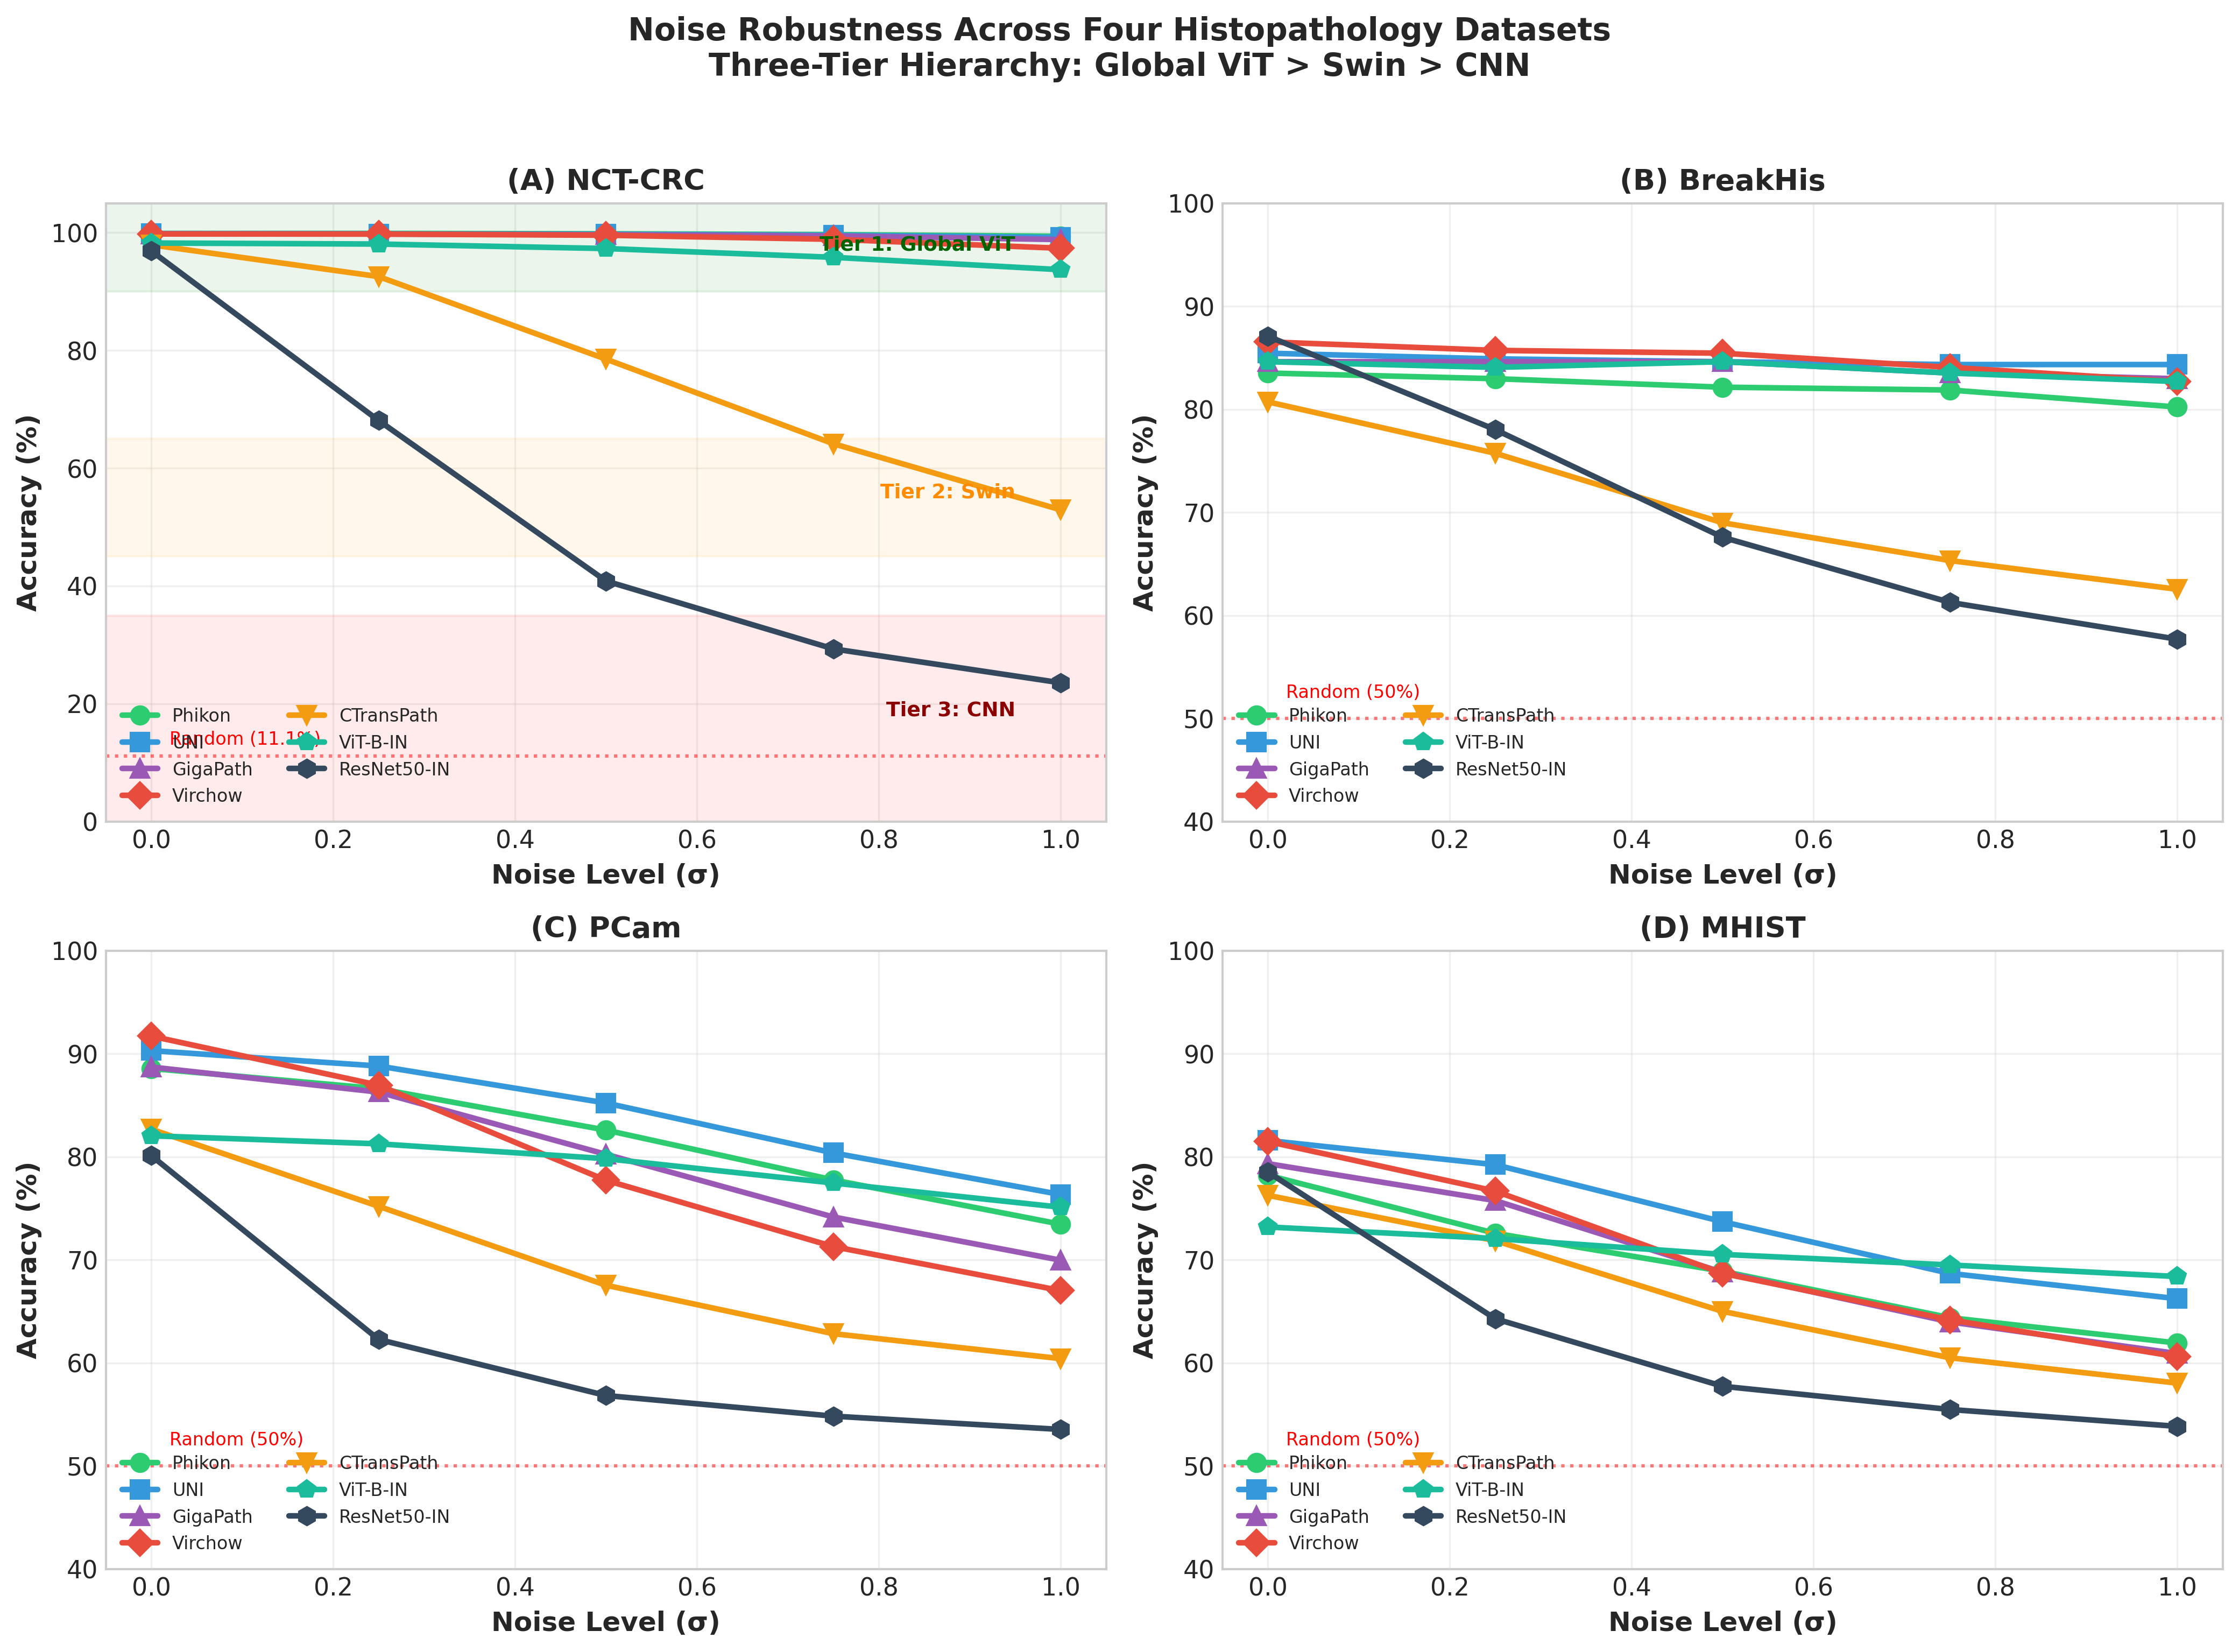

✅ Saved: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/final_figures_paper/fig_noise_robustness_all_datasets.png

📊 Creating Figure 2: BreakHis Analysis...


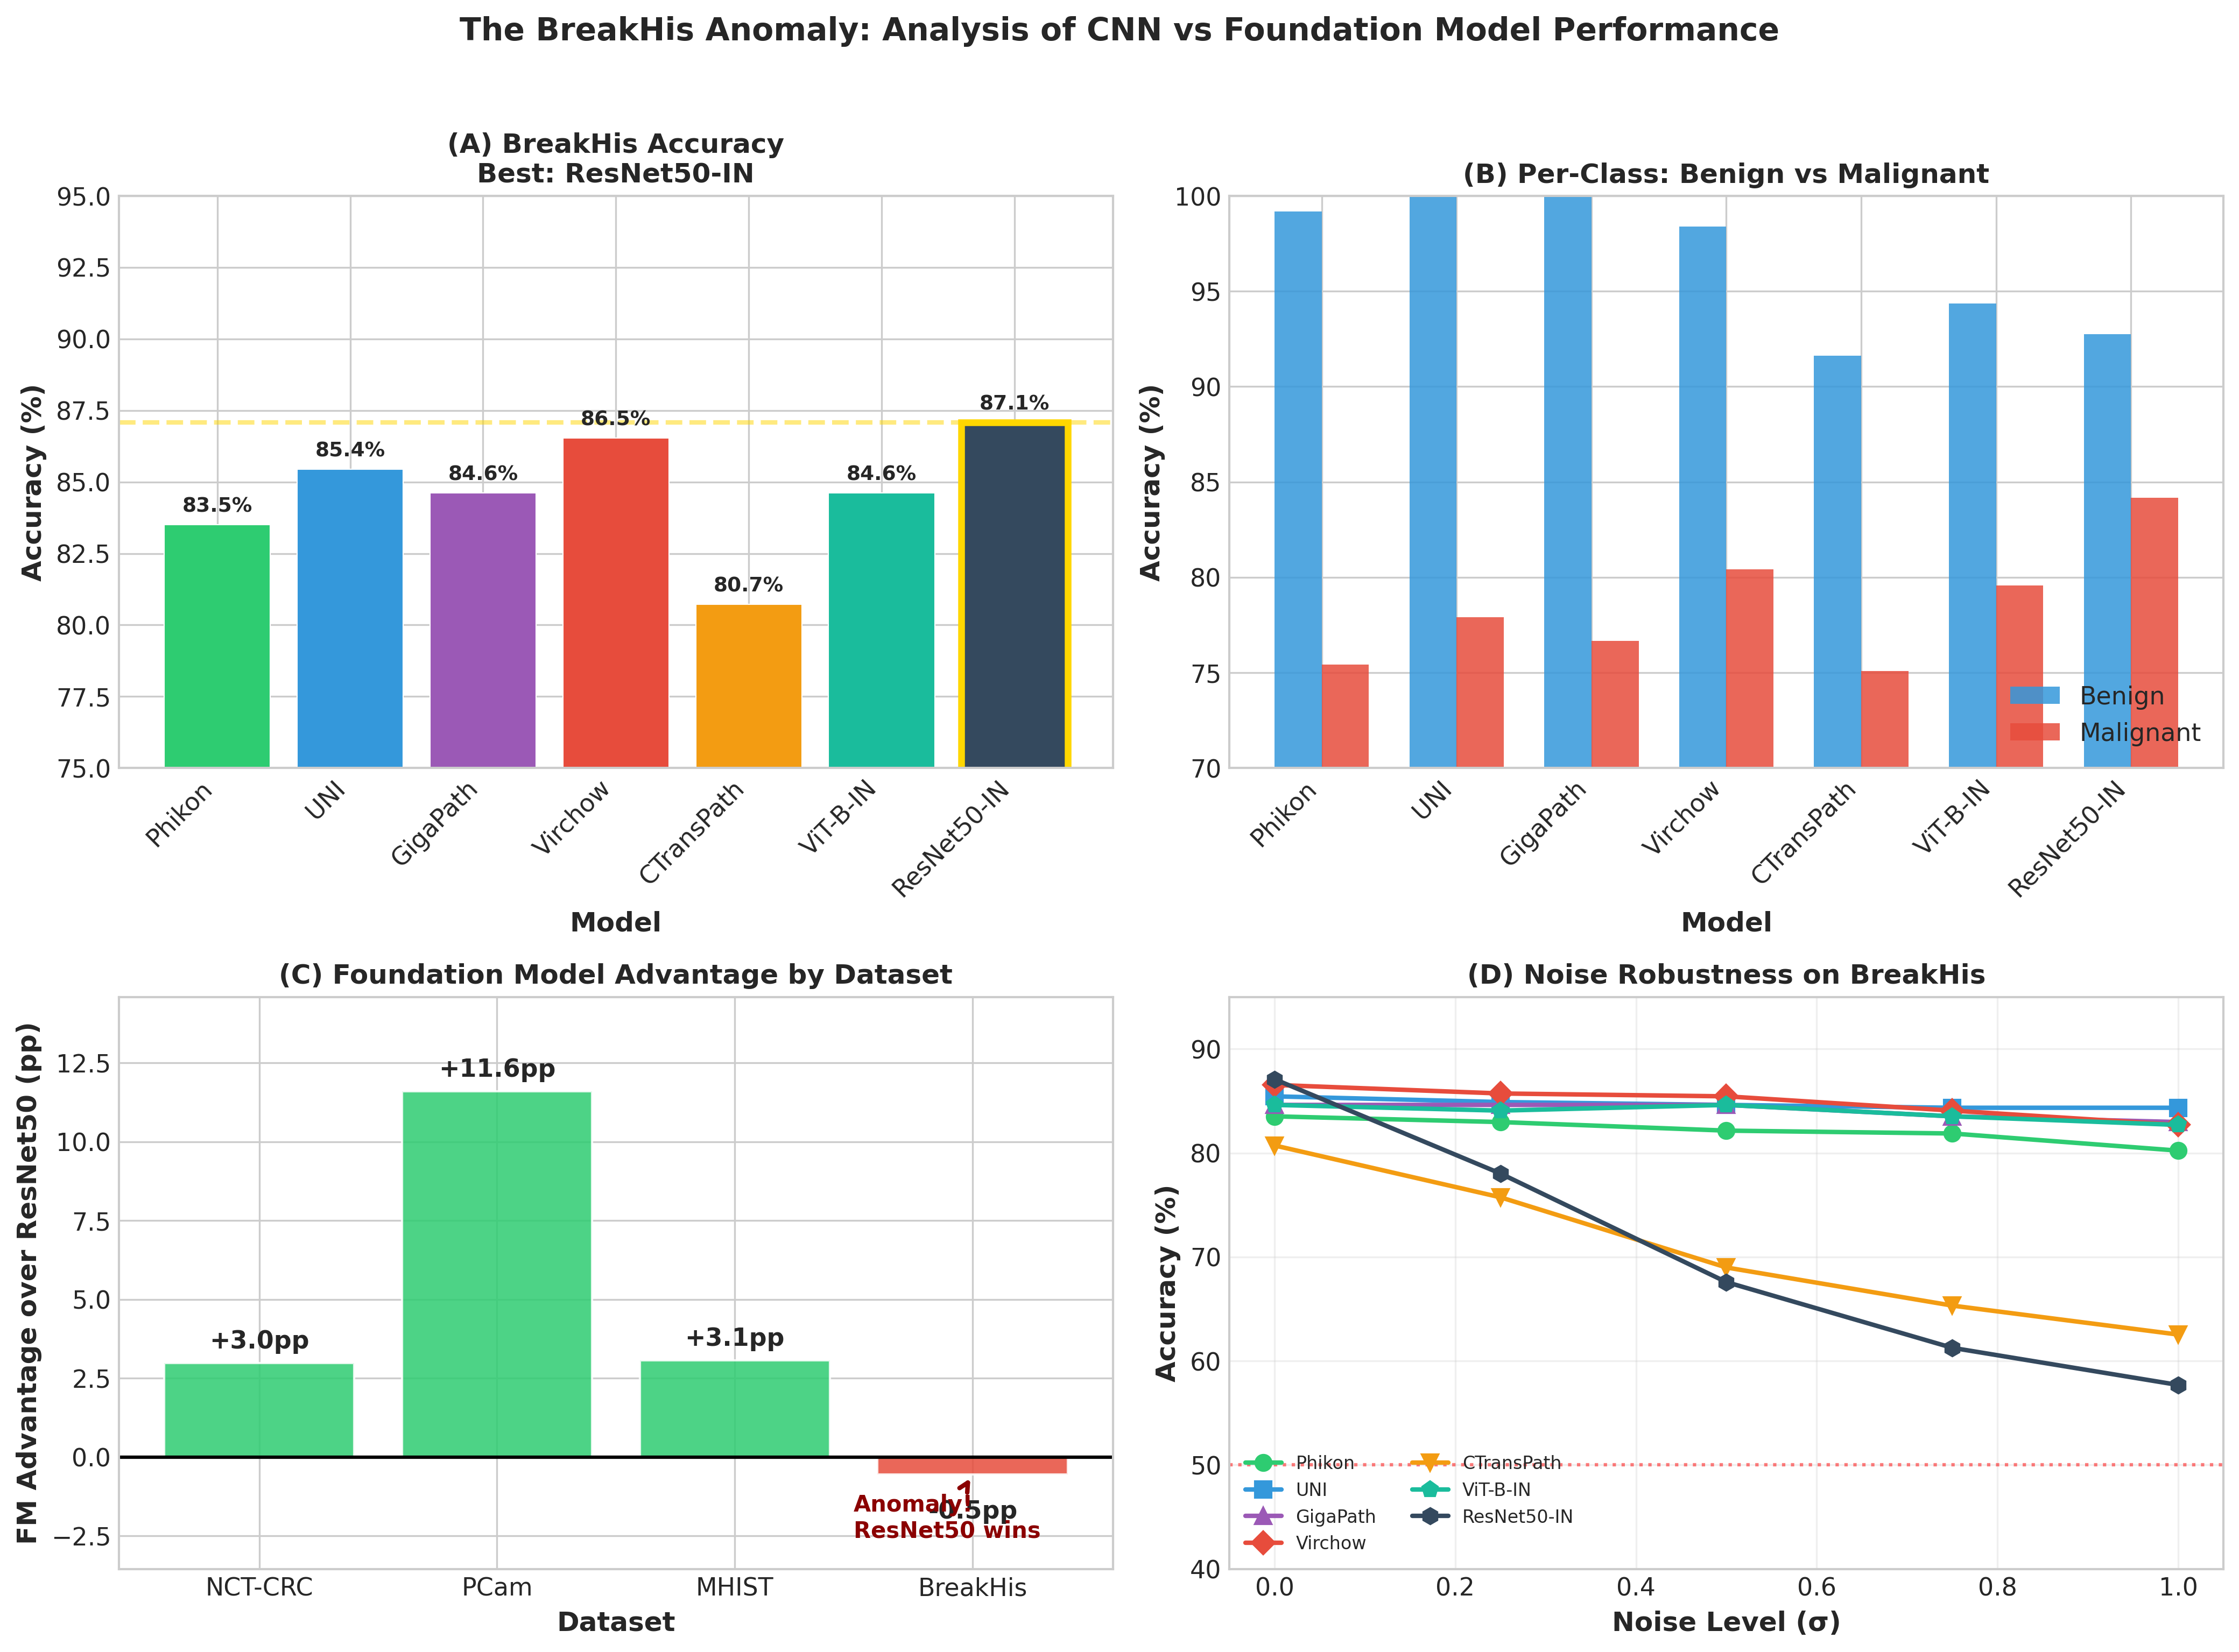

✅ Saved: /content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/final_figures_paper/fig_breakhis_analysis.png

SUMMARY: BASELINE ACCURACY (%)

| Model | NCT-CRC | BreakHis | PCam | MHIST | Mean |
|-------|---------|----------|------|-------|------|
| Phikon          |  99.86% |  83.52% |  88.56% |  78.20% | 87.53% |
| UNI             |  99.81% |  85.44% |  90.29% |  81.58% | 89.28% |
| GigaPath        |  99.79% |  84.62% |  88.70% |  79.32% | 88.11% |
| Virchow         |  99.77% |  86.54% |  91.70% |  81.47% | 89.87% |
| CTransPath      |  97.92% |  80.72% |  82.67% |  76.25% | 84.39% |
| ViT-B-IN        |  98.23% |  84.62% |  82.03% |  73.18% | 84.51% |
| ResNet50-IN     |  96.89% |  87.09% |  80.11% |  78.51% | 85.65% |

SUMMARY: NOISE DROP AT σ=1.0 (pp)

| Model | NCT-CRC | BreakHis | PCam | MHIST |
|-------|---------|----------|------|-------|
| Phikon          |   0.49 |   3.30 |  15.11 |  16.27 |
| UNI             |   0.63 |   1.10 |  13.96 |  15.35 |
| GigaPath        |   0.97 |   

In [ ]:
# ============================================================
# GENERATE: fig_noise_robustness_all_datasets & fig_breakhis_analysis
# CORRECTED PATHS - All 7 models × 4 datasets
# ============================================================

# ============================================================
# CELL 1: Setup
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from scipy import stats
import os
import warnings
warnings.filterwarnings('ignore')

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Paths
BASE_PATH = '/content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS'
OUTPUT_PATH = '/content/drive/MyDrive/COMPLETE_MISSING_EXPERIMENTS/final_figures_paper'
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['figure.dpi'] = 300

print("✅ Setup complete!")

# ============================================================
# CELL 2: CORRECTED Model Paths (All 7 models × All datasets)
# ============================================================

MODELS = {
    'Phikon': {
        'nct': f'{BASE_PATH}/phikon_features.npz',
        'breakhis': f'{BASE_PATH}/breakhis_phikon_100X_features.npz',
        'pcam': f'{BASE_PATH}/pcam_phikon_features.npz',
        'mhist': f'{BASE_PATH}/mhist_phikon_features.npz',
        'nonorm': f'{BASE_PATH}/nonorm_phikon_features.npz',
        'external': f'{BASE_PATH}/Phikon_external_features.npz',
        'color': '#2ecc71',
        'marker': 'o'
    },
    'UNI': {
        'nct': f'{BASE_PATH}/uni_verification_features.npz',  # CORRECT - not uni_features.npz
        'breakhis': f'{BASE_PATH}/breakhis_uni_100X_features.npz',
        'pcam': f'{BASE_PATH}/pcam_uni_features.npz',
        'mhist': f'{BASE_PATH}/mhist_uni_features.npz',
        'nonorm': f'{BASE_PATH}/nonorm_uni_features.npz',
        'external': f'{BASE_PATH}/UNI_external_features.npz',
        'color': '#3498db',
        'marker': 's'
    },
    'GigaPath': {
        'nct': f'{BASE_PATH}/gigapath_features.npz',
        'breakhis': f'{BASE_PATH}/breakhis_gigapath_100X_features.npz',
        'pcam': f'{BASE_PATH}/pcam_gigapath_features.npz',
        'mhist': f'{BASE_PATH}/mhist_gigapath_features.npz',
        'nonorm': f'{BASE_PATH}/nonorm_gigapath_features.npz',
        'external': f'{BASE_PATH}/GigaPath_external_features.npz',
        'color': '#9b59b6',
        'marker': '^'
    },
    'Virchow': {
        'nct': f'{BASE_PATH}/virchow_features.npz',
        'breakhis': f'{BASE_PATH}/breakhis_virchow_100X_features.npz',
        'pcam': f'{BASE_PATH}/pcam_virchow_features.npz',
        'mhist': f'{BASE_PATH}/mhist_virchow_features.npz',
        'nonorm': f'{BASE_PATH}/nonorm_virchow_features.npz',
        'external': f'{BASE_PATH}/Virchow_external_features.npz',
        'color': '#e74c3c',
        'marker': 'D'
    },
    'CTransPath': {
        'nct': f'{BASE_PATH}/ctranspath_nct_features.npz',
        'breakhis': f'{BASE_PATH}/breakhis_ctranspath_features.npz',
        'pcam': f'{BASE_PATH}/pcam_ctranspath_features.npz',
        'mhist': f'{BASE_PATH}/mhist_ctranspath_features.npz',
        'nonorm': f'{BASE_PATH}/nonorm_ctranspath_features.npz',
        'external': f'{BASE_PATH}/CTransPath_external_features.npz',
        'color': '#f39c12',
        'marker': 'v'
    },
    'ViT-B-ImageNet': {
        'nct': f'{BASE_PATH}/vit_imagenet_features.npz',
        'breakhis': f'{BASE_PATH}/breakhis_vit_b_imagenet_100X_features.npz',  # CORRECTED
        'pcam': f'{BASE_PATH}/pcam_vit_b_imagenet_features.npz',  # CORRECTED
        'mhist': f'{BASE_PATH}/mhist_vit_b_imagenet_features.npz',  # CORRECTED
        'nonorm': f'{BASE_PATH}/nonorm_vit_b_imagenet_features.npz',  # CORRECTED
        'external': f'{BASE_PATH}/ViT-B-ImageNet_external_features.npz',  # CORRECTED
        'color': '#1abc9c',
        'marker': 'p'
    },
    'ResNet50-ImageNet': {
        'nct': f'{BASE_PATH}/resnet50_features.npz',
        'breakhis': f'{BASE_PATH}/breakhis_resnet50_imagenet_100X_features.npz',
        'pcam': f'{BASE_PATH}/pcam_resnet50_imagenet_features.npz',
        'mhist': f'{BASE_PATH}/mhist_resnet50_imagenet_features.npz',
        'nonorm': f'{BASE_PATH}/nonorm_resnet50_imagenet_features.npz',
        'external': f'{BASE_PATH}/ResNet50-ImageNet_external_features.npz',
        'color': '#34495e',
        'marker': 'h'
    },
}

# Verify all files exist
print("\n📂 Verifying feature files...")
for model_name, config in MODELS.items():
    print(f"\n{model_name}:")
    for dataset in ['nct', 'breakhis', 'pcam', 'mhist', 'nonorm', 'external']:
        path = config.get(dataset)
        if path and os.path.exists(path):
            print(f"  ✅ {dataset}")
        else:
            print(f"  ❌ {dataset}: {path}")

print("\n✅ Models defined!")

# ============================================================
# CELL 3: Feature Loading Function
# ============================================================

def load_features(path):
    """Load features from npz file with flexible key handling"""
    if not path or not os.path.exists(path):
        return None, None, None, None

    data = np.load(path)
    keys = list(data.keys())

    # Try different key naming conventions
    if 'X_train' in data and 'X_test' in data:
        return data['X_train'], data['y_train'], data['X_test'], data['y_test']
    elif 'train_features' in data and 'test_features' in data:
        return data['train_features'], data['train_labels'], data['test_features'], data['test_labels']
    elif 'features' in data and 'labels' in data:
        # Single array - need to split
        X, y = data['features'], data['labels']
        from sklearn.model_selection import train_test_split
        return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    else:
        # Try to figure out keys
        print(f"  Unknown keys: {keys}")
        # Assume first two are features and labels
        if len(keys) >= 2:
            X, y = data[keys[0]], data[keys[1]]
            from sklearn.model_selection import train_test_split
            return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
        return None, None, None, None

def evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels):
    """Train classifier and evaluate at different noise levels"""
    clf = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
    clf.fit(X_train, y_train)

    accuracies = []
    for sigma in sigma_levels:
        if sigma == 0:
            X_noisy = X_test
        else:
            np.random.seed(42)
            noise = np.random.randn(*X_test.shape) * sigma
            X_noisy = X_test + noise

        y_pred = clf.predict(X_noisy)
        acc = accuracy_score(y_test, y_pred) * 100
        accuracies.append(acc)

    return accuracies, clf

print("✅ Functions defined!")

# ============================================================
# CELL 4: Evaluate All Models on All Datasets
# ============================================================

print("\n" + "="*70)
print("EVALUATING ALL MODELS ON ALL DATASETS")
print("="*70)

sigma_levels = [0.0, 0.25, 0.5, 0.75, 1.0]

# Store all results
all_results = {}
noise_results = {'NCT-CRC': {}, 'BreakHis': {}, 'PCam': {}, 'MHIST': {}}
baseline_accuracy = {'NCT-CRC': {}, 'BreakHis': {}, 'PCam': {}, 'MHIST': {}}

for model_name, config in MODELS.items():
    print(f"\n{'='*50}")
    print(f"  {model_name}")
    print(f"{'='*50}")

    all_results[model_name] = {}

    # NCT-CRC
    print("  Loading NCT-CRC...")
    X_train, y_train, X_test, y_test = load_features(config['nct'])
    if X_train is not None:
        accs, clf = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['NCT-CRC'][model_name] = accs
        baseline_accuracy['NCT-CRC'][model_name] = accs[0]
        all_results[model_name]['nct'] = {'accuracy': accs[0], 'noise_curve': accs, 'clf': clf,
                                           'X_test': X_test, 'y_test': y_test}
        print(f"    ✓ NCT-CRC: {accs[0]:.2f}% → {accs[-1]:.2f}% (drop: {accs[0]-accs[-1]:.1f} pp)")

    # BreakHis
    print("  Loading BreakHis...")
    X_train, y_train, X_test, y_test = load_features(config['breakhis'])
    if X_train is not None:
        accs, clf = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['BreakHis'][model_name] = accs
        baseline_accuracy['BreakHis'][model_name] = accs[0]

        # Additional BreakHis analysis
        y_pred = clf.predict(X_test)
        benign_mask = y_test == 0
        malignant_mask = y_test == 1
        benign_acc = accuracy_score(y_test[benign_mask], y_pred[benign_mask]) * 100 if benign_mask.sum() > 0 else 0
        malignant_acc = accuracy_score(y_test[malignant_mask], y_pred[malignant_mask]) * 100 if malignant_mask.sum() > 0 else 0

        all_results[model_name]['breakhis'] = {
            'accuracy': accs[0], 'noise_curve': accs,
            'benign_acc': benign_acc, 'malignant_acc': malignant_acc,
            'y_test': y_test, 'y_pred': y_pred
        }
        print(f"    ✓ BreakHis: {accs[0]:.2f}% (Benign: {benign_acc:.1f}%, Malignant: {malignant_acc:.1f}%)")

    # PCam
    print("  Loading PCam...")
    X_train, y_train, X_test, y_test = load_features(config['pcam'])
    if X_train is not None:
        accs, clf = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['PCam'][model_name] = accs
        baseline_accuracy['PCam'][model_name] = accs[0]
        all_results[model_name]['pcam'] = {'accuracy': accs[0], 'noise_curve': accs}
        print(f"    ✓ PCam: {accs[0]:.2f}% → {accs[-1]:.2f}%")

    # MHIST
    print("  Loading MHIST...")
    X_train, y_train, X_test, y_test = load_features(config['mhist'])
    if X_train is not None:
        accs, clf = evaluate_noise_robustness(X_train, y_train, X_test, y_test, sigma_levels)
        noise_results['MHIST'][model_name] = accs
        baseline_accuracy['MHIST'][model_name] = accs[0]
        all_results[model_name]['mhist'] = {'accuracy': accs[0], 'noise_curve': accs}
        print(f"    ✓ MHIST: {accs[0]:.2f}% → {accs[-1]:.2f}%")

print("\n✅ All evaluations complete!")

# ============================================================
# CELL 5: FIGURE 1 - Noise Robustness All Datasets (2×2 Grid)
# ============================================================

print("\n📊 Creating Figure 1: Noise Robustness All Datasets...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

datasets = ['NCT-CRC', 'BreakHis', 'PCam', 'MHIST']
panel_labels = ['(A)', '(B)', '(C)', '(D)']
random_chance = {'NCT-CRC': 11.1, 'BreakHis': 50, 'PCam': 50, 'MHIST': 50}

for idx, (dataset, ax) in enumerate(zip(datasets, axes)):
    if dataset in noise_results and len(noise_results[dataset]) > 0:
        for model_name, config in MODELS.items():
            if model_name in noise_results[dataset]:
                accs = noise_results[dataset][model_name]
                ax.plot(sigma_levels, accs,
                       marker=config['marker'],
                       color=config['color'],
                       linewidth=2.5,
                       markersize=8,
                       label=model_name.replace('-ImageNet', '-IN'))

        ax.set_xlabel('Noise Level (σ)', fontsize=12, fontweight='bold')
        ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
        ax.set_title(f'{panel_labels[idx]} {dataset}', fontsize=13, fontweight='bold')

        # Set y-axis based on dataset
        if dataset == 'NCT-CRC':
            ax.set_ylim(0, 105)
            # Add tier shading
            ax.axhspan(90, 105, alpha=0.08, color='green')
            ax.axhspan(45, 65, alpha=0.08, color='orange')
            ax.axhspan(0, 35, alpha=0.08, color='red')
            ax.text(0.95, 97, 'Tier 1: Global ViT', fontsize=9, ha='right', color='darkgreen', fontweight='bold')
            ax.text(0.95, 55, 'Tier 2: Swin', fontsize=9, ha='right', color='darkorange', fontweight='bold')
            ax.text(0.95, 18, 'Tier 3: CNN', fontsize=9, ha='right', color='darkred', fontweight='bold')
        else:
            ax.set_ylim(40, 100)

        ax.axhline(y=random_chance[dataset], color='red', linestyle=':', alpha=0.5, linewidth=1.5)
        ax.text(0.02, random_chance[dataset]+2, f'Random ({random_chance[dataset]}%)', fontsize=8, color='red')

        ax.grid(True, alpha=0.3)
        ax.legend(loc='lower left', fontsize=8, ncol=2)

plt.suptitle('Noise Robustness Across Four Histopathology Datasets\nThree-Tier Hierarchy: Global ViT > Swin > CNN',
            fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(f'{OUTPUT_PATH}/fig_noise_robustness_all_datasets.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_PATH}/fig_noise_robustness_all_datasets.pdf', bbox_inches='tight')
plt.show()

print(f"✅ Saved: {OUTPUT_PATH}/fig_noise_robustness_all_datasets.png")

# ============================================================
# CELL 6: FIGURE 2 - BreakHis Analysis (4-Panel)
# ============================================================

print("\n📊 Creating Figure 2: BreakHis Analysis...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Get BreakHis results
breakhis_models = [m for m in MODELS.keys() if 'breakhis' in all_results.get(m, {})]
breakhis_accs = [all_results[m]['breakhis']['accuracy'] for m in breakhis_models]
model_colors = [MODELS[m]['color'] for m in breakhis_models]
model_names_short = [m.replace('-ImageNet', '-IN') for m in breakhis_models]

# Panel A: Overall accuracy comparison
ax1 = axes[0, 0]
bars = ax1.bar(model_names_short, breakhis_accs, color=model_colors, edgecolor='white', linewidth=0.5)

# Highlight best performer
max_idx = np.argmax(breakhis_accs)
bars[max_idx].set_edgecolor('gold')
bars[max_idx].set_linewidth(3)

for bar, acc in zip(bars, breakhis_accs):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{acc:.1f}%',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_xlabel('Model', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax1.set_title(f'(A) BreakHis Accuracy\nBest: {breakhis_models[max_idx].replace("-ImageNet", "-IN")}',
             fontsize=12, fontweight='bold')
ax1.set_ylim(75, 95)
ax1.axhline(y=max(breakhis_accs), color='gold', linestyle='--', alpha=0.5, linewidth=2)
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')

# Panel B: Per-class accuracy (Benign vs Malignant)
ax2 = axes[0, 1]
x = np.arange(len(breakhis_models))
width = 0.35

benign_accs = [all_results[m]['breakhis']['benign_acc'] for m in breakhis_models]
malignant_accs = [all_results[m]['breakhis']['malignant_acc'] for m in breakhis_models]

bars1 = ax2.bar(x - width/2, benign_accs, width, label='Benign', color='#3498db', alpha=0.85)
bars2 = ax2.bar(x + width/2, malignant_accs, width, label='Malignant', color='#e74c3c', alpha=0.85)

ax2.set_xlabel('Model', fontsize=12, fontweight='bold')
ax2.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax2.set_title('(B) Per-Class: Benign vs Malignant', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(model_names_short, rotation=45, ha='right')
ax2.set_ylim(70, 100)
ax2.legend(loc='lower right')

# Panel C: FM Advantage comparison across datasets
ax3 = axes[1, 0]

# Calculate FM advantage for each dataset
datasets_compare = ['NCT-CRC', 'PCam', 'MHIST', 'BreakHis']
fm_advantage = []

for dataset in datasets_compare:
    if dataset in baseline_accuracy and len(baseline_accuracy[dataset]) > 0:
        # Get best FM accuracy (exclude ImageNet baselines)
        fm_accs = [baseline_accuracy[dataset].get(m, 0) for m in ['Phikon', 'UNI', 'GigaPath', 'Virchow', 'CTransPath']
                   if m in baseline_accuracy[dataset]]
        resnet_acc = baseline_accuracy[dataset].get('ResNet50-ImageNet', 0)

        if fm_accs and resnet_acc:
            best_fm = max(fm_accs)
            fm_advantage.append(best_fm - resnet_acc)
        else:
            fm_advantage.append(0)
    else:
        fm_advantage.append(0)

colors_adv = ['#2ecc71' if adv > 0 else '#e74c3c' for adv in fm_advantage]
bars = ax3.bar(datasets_compare, fm_advantage, color=colors_adv, edgecolor='white', alpha=0.85)

for bar, adv in zip(bars, fm_advantage):
    ypos = bar.get_height() + 0.3 if adv > 0 else bar.get_height() - 0.8
    ax3.text(bar.get_x() + bar.get_width()/2, ypos, f'{adv:+.1f}pp',
            ha='center', va='bottom' if adv > 0 else 'top',
            fontsize=11, fontweight='bold')

ax3.set_xlabel('Dataset', fontsize=12, fontweight='bold')
ax3.set_ylabel('FM Advantage over ResNet50 (pp)', fontsize=12, fontweight='bold')
ax3.set_title('(C) Foundation Model Advantage by Dataset', fontsize=12, fontweight='bold')
ax3.axhline(y=0, color='black', linewidth=1.5)
ax3.set_ylim(min(fm_advantage)-3, max(fm_advantage)+3)

# Highlight BreakHis anomaly if negative
if fm_advantage[-1] < 0:
    ax3.annotate('Anomaly!\nResNet50 wins', xy=(3, fm_advantage[-1]), xytext=(2.5, fm_advantage[-1]-2),
                fontsize=10, fontweight='bold', color='darkred',
                arrowprops=dict(arrowstyle='->', color='darkred', lw=2))

# Panel D: Noise robustness comparison on BreakHis
ax4 = axes[1, 1]

for model_name in breakhis_models:
    if model_name in noise_results['BreakHis']:
        accs = noise_results['BreakHis'][model_name]
        ax4.plot(sigma_levels, accs,
                marker=MODELS[model_name]['marker'],
                color=MODELS[model_name]['color'],
                linewidth=2, markersize=7,
                label=model_name.replace('-ImageNet', '-IN'))

ax4.set_xlabel('Noise Level (σ)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax4.set_title('(D) Noise Robustness on BreakHis', fontsize=12, fontweight='bold')
ax4.set_ylim(40, 95)
ax4.axhline(y=50, color='red', linestyle=':', alpha=0.5)
ax4.legend(loc='lower left', fontsize=8, ncol=2)
ax4.grid(True, alpha=0.3)

plt.suptitle('The BreakHis Anomaly: Analysis of CNN vs Foundation Model Performance',
            fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(f'{OUTPUT_PATH}/fig_breakhis_analysis.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_PATH}/fig_breakhis_analysis.pdf', bbox_inches='tight')
plt.show()

print(f"✅ Saved: {OUTPUT_PATH}/fig_breakhis_analysis.png")

# ============================================================
# CELL 7: Print Summary Tables
# ============================================================

print("\n" + "="*70)
print("SUMMARY: BASELINE ACCURACY (%)")
print("="*70)

print("\n| Model | NCT-CRC | BreakHis | PCam | MHIST | Mean |")
print("|-------|---------|----------|------|-------|------|")
for model in MODELS.keys():
    row = f"| {model.replace('-ImageNet', '-IN'):15} |"
    accs = []
    for dataset in ['NCT-CRC', 'BreakHis', 'PCam', 'MHIST']:
        if model in baseline_accuracy.get(dataset, {}):
            acc = baseline_accuracy[dataset][model]
            row += f" {acc:6.2f}% |"
            accs.append(acc)
        else:
            row += "    N/A |"
    if accs:
        row += f" {np.mean(accs):.2f}% |"
    else:
        row += "  N/A |"
    print(row)

print("\n" + "="*70)
print("SUMMARY: NOISE DROP AT σ=1.0 (pp)")
print("="*70)

print("\n| Model | NCT-CRC | BreakHis | PCam | MHIST |")
print("|-------|---------|----------|------|-------|")
for model in MODELS.keys():
    row = f"| {model.replace('-ImageNet', '-IN'):15} |"
    for dataset in ['NCT-CRC', 'BreakHis', 'PCam', 'MHIST']:
        if model in noise_results.get(dataset, {}):
            accs = noise_results[dataset][model]
            drop = accs[0] - accs[-1]
            row += f" {drop:6.2f} |"
        else:
            row += "    N/A |"
    print(row)

print("\n" + "="*70)
print("✅ ALL FIGURES GENERATED!")
print("="*70)
print(f"\nOutput directory: {OUTPUT_PATH}")
print("\nGenerated files:")
print("  1. fig_noise_robustness_all_datasets.png/pdf")
print("  2. fig_breakhis_analysis.png/pdf")